# Short-Term Air Passenger Demand Forecasting via Adaptive Holt's Linear Trend Method

### AeroCast — project report and analysis

**Course:** Applied Time Series Analysis (ATSA)

**Team:** Riti Shah · Pradhi Kanani · Shreeya

**Date:** 21 October 2026

---

**In one sentence.** We forecast daily passenger demand at seven major U.S. airports with
*AR-Holt*, a damped Holt's linear trend method whose smoothing parameter adapts to shocks
and whose updates are protected from one-off outliers, and we test it honestly against
seven benchmarks — in normal times, during the COVID-19 collapse, and on two classic
textbook series.

**Contents.** 2 Problem · 3 Data · 4 EDA · 5 Decomposition · 6 Stationarity · 7 Theory ·
8 Implementation check · 9 Fitted parameters · 10 How the model adapts · 11 Residual
diagnostics · 12 Results · 13 Application · 14 Conclusions · 15 References

In [1]:
# Setup: imports, plotting style and colour palette used for every figure.
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

from airdemand import config
from airdemand.data import load_series, load_tsa_daily, load_hourly_profile
from airdemand.seasonal import SeasonalAdjuster
from airdemand.models import MODELS, Holt, AdaptiveRobustHolt, holt_filter
from airdemand.events import event_table
from airdemand.capacity import forecast_at_quantile, staffing_plan, peak_hours

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "results"                    # v2: rolling seasonal indices (default)
RES1 = RES / "v1_fixed_indices"           # v1: seasonal indices fixed from the training span

# Palette: the proposed model in orange; the three main comparators in blue,
# aqua and violet; the simple baselines in grey (told apart by line style).
COL = {"AR-Holt": "#eb6834", "Holt": "#2a78d6", "DampedHolt": "#1baf7a",
       "HoltWinters": "#6250d6", "TriggLeachHolt": "#8a8984", "SES": "#a3a29c",
       "SeasonalNaive": "#6f6e69", "Naive": "#bdbcb6"}
STYLE = {"Naive": ":", "SeasonalNaive": "--", "SES": "-.", "TriggLeachHolt": (0, (5, 1, 1, 1))}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SHOCK_FILL = "#f9d8c9"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 1.6,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

def thousands(ax, axis="y"):
    fmt = plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

print("ready —", ROOT)

ready — /Users/ritishah/Desktop/air-demand-forecasting


## 2. Problem statement and motivation

**Why short-term demand matters.** Airports and airlines plan on a *days-to-weeks* horizon:
how many security lanes to open tomorrow morning, how many officers to roster next week,
whether to up-gauge an aircraft or add a frequency. Under-forecasting creates queues and
missed connections; over-forecasting wastes staff hours and seats. A forecast with an
honest *range* (prediction interval) lets planners choose a safety margin — e.g. staff to the
80th percentile of demand.

**Why fixed smoothing fails under shocks.** Exponential smoothing methods (SES, Holt,
Holt–Winters) update their level with a *fixed* weight $\alpha$ on the newest error:

* a **small** $\alpha$ gives smooth, stable forecasts in normal times, but reacts very slowly
  when demand collapses (COVID-19: −95% within weeks) — the model keeps forecasting
  pre-crisis traffic for weeks;
* a **large** $\alpha$ reacts fast, but then chases every one-off spike or dip
  (Thanksgiving, a snowstorm) and becomes noisy.

No single $\alpha$ is right for both. **Our idea (AR-Holt):** let $\alpha$ *move* — small in
calm periods, large during persistent shifts — using the *tracking signal* to tell the two
apart, and *clip* isolated outliers so that a single holiday cannot drag the level, unless
the shift turns out to be persistent.

**Research questions.**
1. Does AR-Holt forecast better than fixed-parameter Holt variants during a structural shock (COVID-19)?
2. Does it lose accuracy in normal operations, where adaptivity is not needed?
3. Which ingredient (adaptive $\alpha$, robust clipping) contributes where?
4. Are its prediction intervals well calibrated?

## 3. Data description

| Dataset | Frequency | Source |
|---|---|---|
| TSA checkpoint throughput, 7 hub airports (ATL, DFW, DEN, ORD, LAX, JFK, SEA) | hourly → daily | U.S. Transportation Security Administration FOIA reading room (public domain), parsed to CSV by the open-source repository `mikelor/TsaThroughput` |
| AirPassengers (Box & Jenkins) | monthly | R `datasets`, via `vincentarelbundock/Rdatasets` |
| Australian air passengers (Hyndman & Athanasopoulos, FPP3) | annual | R `fpp3`, via `vincentarelbundock/Rdatasets` |

**Processing** (`scripts/prepare_data.py`): the daily total of an airport is the sum over all
of its checkpoints and hours. The same few days are missing for every airport; each missing
day is filled with the average of the same weekday one week before and one week after, and
flagged `imputed = 1`. `ALL7` is the sum of the seven airports. Genuine shocks (COVID,
holidays, storms) are **not** removed — they are exactly what an adaptive model must handle.

In [2]:
daily = load_tsa_daily()
rows = []
for code_ in config.AIRPORTS + [config.ALL7]:
    d = daily[daily.airport == code_].set_index("date")["passengers"]
    rows.append({"series": code_, "start": d.index.min().date(), "end": d.index.max().date(),
                 "days": len(d), "imputed days": int(daily[(daily.airport == code_)].imputed.sum()),
                 "mean 2019": d["2019"].mean(), "mean 2020": d["2020"].mean(),
                 "mean Jun24–May25": d["2024-06":"2025-05"].mean(),
                 "lowest day": d.idxmin().date(), "lowest value": d.min()})
coverage = pd.DataFrame(rows).set_index("series")
display(coverage.style.format({c: "{:,.0f}" for c in ["mean 2019", "mean 2020", "mean Jun24–May25", "lowest value"]}))
imp = daily[(daily.airport == "ALL7") & (daily.imputed == 1)].date.dt.date.tolist()
print("Imputed days (identical for every airport):", ", ".join(map(str, imp)))

,start,end,days,imputed days,mean 2019,mean 2020,mean Jun24–May25,lowest day,lowest value
series,,,,,,,,,
ATL,2018-12-30,2025-05-31,2345,8,"70,400","28,357","82,600",2020-04-08,"2,345"
DFW,2018-12-30,2025-05-31,2345,8,"58,626","27,136","71,320",2020-04-07,"3,522"
DEN,2018-12-30,2025-05-31,2345,8,"63,384","28,925","64,976",2020-04-15,"2,026"
ORD,2018-12-30,2025-05-31,2345,8,"81,581","29,592","81,755",2020-04-12,"4,660"
LAX,2018-12-30,2025-05-31,2345,8,"112,655","38,473","98,634",2020-04-14,"4,430"
JFK,2018-12-30,2025-05-31,2345,8,"89,992","25,466","91,463",2020-04-21,"1,640"
SEA,2018-12-30,2025-05-31,2345,8,"53,433","19,595","54,883",2020-04-14,"2,377"
ALL7,2018-12-30,2025-05-31,2345,8,"530,070","197,544","545,631",2020-04-14,"23,948"


Imputed days (identical for every airport): 2022-07-02, 2024-11-17, 2024-11-18, 2024-11-19, 2024-11-20, 2024-11-21, 2024-11-22, 2024-11-23


In [3]:
ap, _ = load_series("AirPassengers")
au, _ = load_series("Australia")
classic = pd.DataFrame({
    "series": ["AirPassengers (thousands / month)", "Australia (millions / year)"],
    "start": [ap.index[0].strftime("%Y-%m"), au.index[0].year],
    "end": [ap.index[-1].strftime("%Y-%m"), au.index[-1].year],
    "n": [len(ap), len(au)], "min": [ap.min(), au.min()], "max": [ap.max(), au.max()],
    "mean": [ap.mean(), au.mean()]}).set_index("series")
display(classic)

,start,end,n,min,max,mean
series,,,,,,
AirPassengers (thousands / month),1949-01,1960-12,144,104.000,622.000,280.299
Australia (millions / year),1970,2016,47,7.319,72.598,30.110


## 4. Exploratory data analysis

### 4.1 All seven airports over time
Each panel shows daily throughput (thin grey) and its 28-day centred mean (blue). All
airports share the COVID collapse of March–April 2020 and a recovery that took roughly
three years.

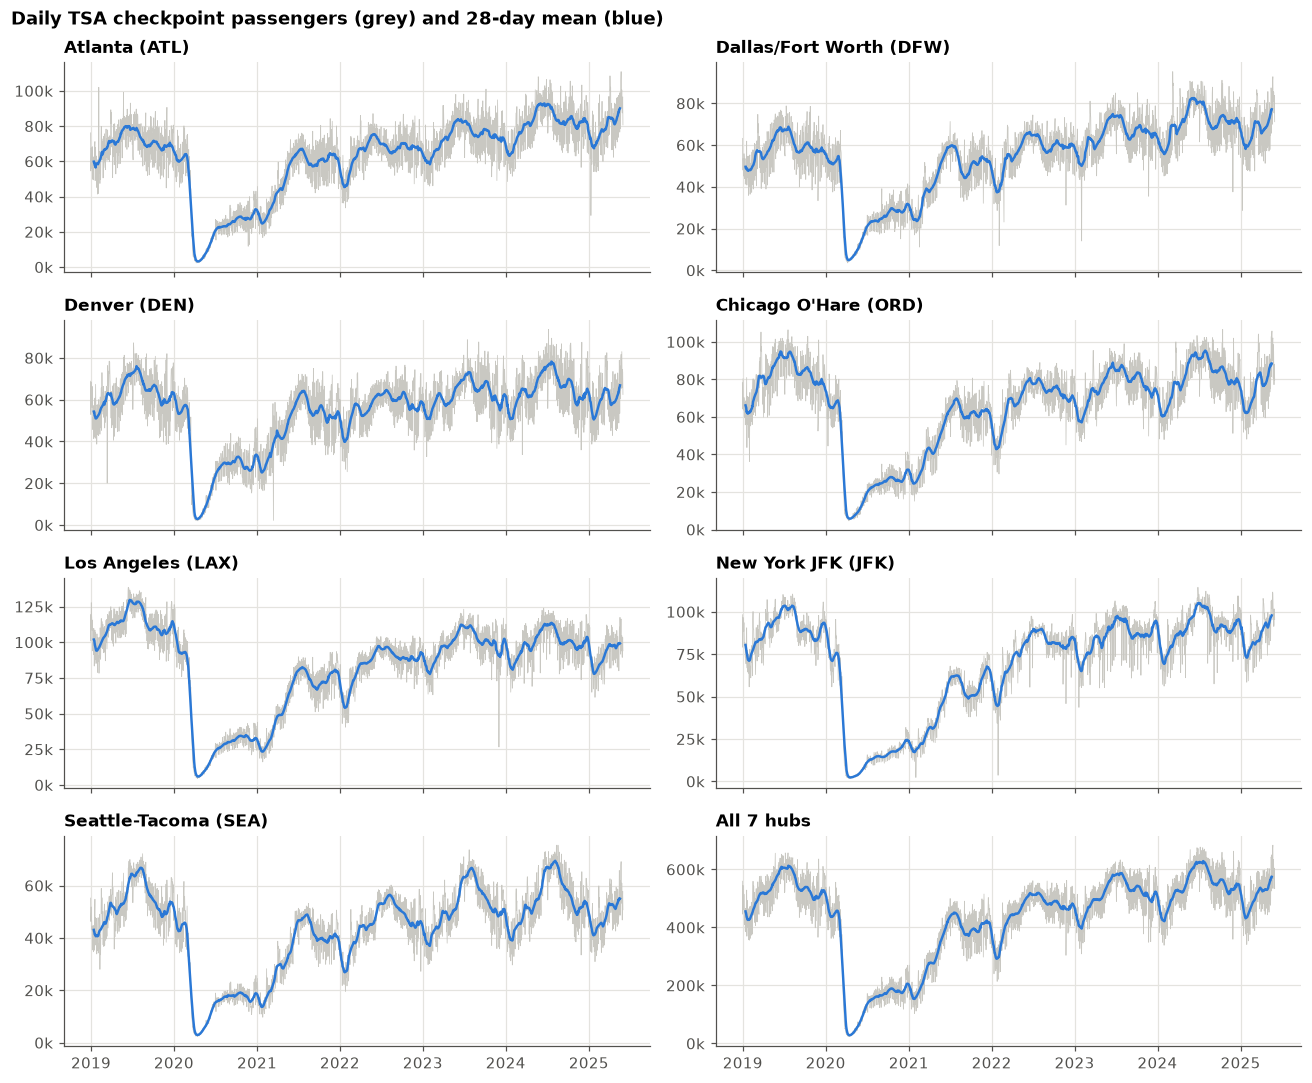

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
for ax, code_ in zip(axes.flat, config.AIRPORTS + [config.ALL7]):
    s, _ = load_series(code_)
    ax.plot(s.index, s, color="#c9c8c2", lw=0.5)
    ax.plot(s.index, s.rolling(28, center=True).mean(), color=COL["Holt"], lw=1.6)
    ax.set_title(config.AIRPORT_NAMES[code_], loc="left", fontsize=11)
    thousands(ax)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Daily TSA checkpoint passengers (grey) and 28-day mean (blue)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "01_airports_over_time")

### 4.2 Day-of-week pattern
Seasonal indices estimated with the same method the models use (median ratio to a centred
7-day moving average, last 26 weeks of data). An index of 1.05 means that weekday is 5%
busier than the weekly average.

,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
ATL,1.057,0.848,0.912,1.095,1.118,0.889,1.081
DFW,1.045,0.854,0.953,1.139,1.102,0.852,1.056
DEN,1.031,0.814,0.901,1.104,1.140,0.878,1.133
ORD,1.024,0.852,0.944,1.114,1.099,0.905,1.062
LAX,1.023,0.863,0.919,1.068,1.091,0.945,1.090
JFK,0.980,0.893,0.947,1.073,1.059,0.998,1.051
SEA,1.008,0.862,0.926,1.111,1.122,0.894,1.076
ALL7,1.018,0.861,0.929,1.095,1.095,0.923,1.079


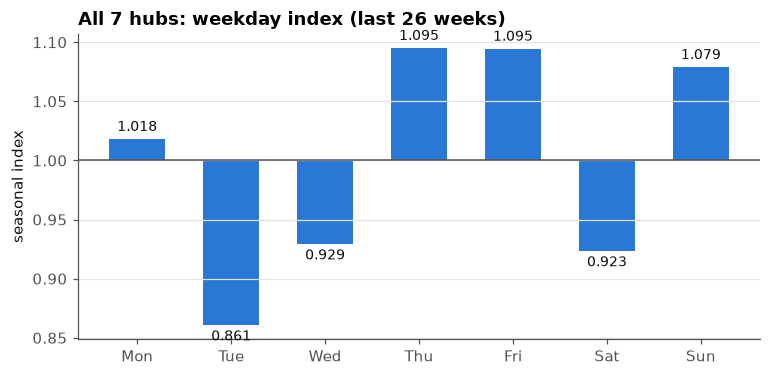

In [5]:
idx_tab = {}
for code_ in config.AIRPORTS + [config.ALL7]:
    s, _ = load_series(code_)
    sa = SeasonalAdjuster(7, window=26 * 7).fit(s)
    idx_tab[code_] = sa.index_table(s.index[-7:])
weekday_idx = pd.DataFrame(idx_tab).loc[["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]]
display(weekday_idx.T.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

fig, ax = plt.subplots(figsize=(8, 3.6))
w = weekday_idx["ALL7"]
bars = ax.bar(w.index.str[:3], w.values - 1, bottom=1, color=COL["Holt"], width=0.6)
ax.axhline(1, color=MUTED, lw=1)
for b, v in zip(bars, w.values):
    ax.text(b.get_x() + b.get_width() / 2, v + (0.004 if v >= 1 else -0.004), f"{v:.3f}",
            ha="center", va="bottom" if v >= 1 else "top", fontsize=9, color=INK)
ax.set_ylabel("seasonal index")
ax.set_title("All 7 hubs: weekday index (last 26 weeks)", loc="left")
ax.grid(axis="x", visible=False)
save(fig, "02_weekday_pattern")

**Does the weekday pattern drift?** The models' default (v2) re-estimates these indices at every
day, from the 26 weeks ending that day only. The heatmap shows those rolling indices for the
combined series: red = busier than the weekly average, blue = quieter. If the pattern were
stable, every row would be one flat colour.

,min in test year,max in test year,fixed (v1) value,range
Mon,1.003,1.044,1.003,0.041
Tue,0.851,0.921,0.890,0.070
Wed,0.917,0.975,0.961,0.058
Thu,1.063,1.095,1.095,0.033
Fri,1.038,1.104,1.080,0.066
Sat,0.901,0.928,0.912,0.028
Sun,1.056,1.107,1.060,0.050


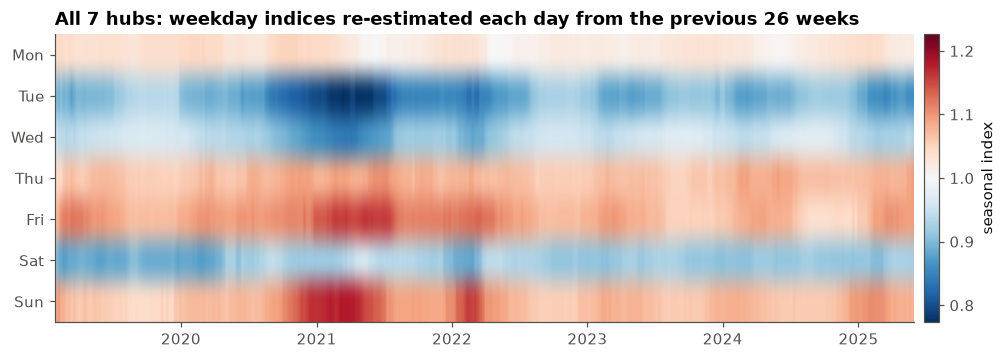

In [6]:
from airdemand.seasonal import season_positions
s, _ = load_series("ALL7")
sa_roll = SeasonalAdjuster(7, window=26 * 7, mode="rolling")
S = sa_roll.origin_indices(s)                      # row t = indices known on day t
# Reorder columns Monday..Sunday using a known Monday in the data
mon = s.index[s.index.dayofweek == 0][0]
cols = season_positions(pd.date_range(mon, periods=7, freq="D"), 7)
roll = pd.DataFrame(S[:, cols], index=s.index, columns=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
weekly = roll.iloc[27::7]                           # one row per week, after the warm-up
fig, ax = plt.subplots(figsize=(12, 3.4))
lim = np.abs(weekly.values - 1).max()
im = ax.imshow(weekly.T.values, aspect="auto", cmap="RdBu_r", vmin=1 - lim, vmax=1 + lim,
               extent=[mdates.date2num(weekly.index[0]), mdates.date2num(weekly.index[-1]), 6.5, -0.5])
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_yticks(range(7), weekly.columns); ax.grid(False)
fig.colorbar(im, ax=ax, pad=0.01).set_label("seasonal index")
ax.set_title("All 7 hubs: weekday indices re-estimated each day from the previous 26 weeks", loc="left")
save(fig, "02b_rolling_weekday_indices")
test_year = roll["2024-06-01":"2025-05-31"]
drift = pd.DataFrame({"min in test year": test_year.min(), "max in test year": test_year.max(),
                      "fixed (v1) value": roll.loc[pd.Timestamp("2024-05-31")]})
drift["range"] = drift["max in test year"] - drift["min in test year"]
display(drift.style.format("{:.3f}"))

### 4.3 The COVID collapse and recovery
Traffic as a percentage of the same weekday 52 weeks earlier would be distorted after 2020,
so we compare every day with the **same weekday of 2019** (364 days × k earlier).

Lowest 7-day average: 4.8% of 2019 on 2020-04-13
  mean for 2020:  38.9% of 2019
  mean for 2021:  63.3% of 2019
  mean for 2022:  85.6% of 2019
  mean for 2023:  97.0% of 2019
First day after the low that the 7-day mean was back to ≥95% of 2019: 2022-08-30


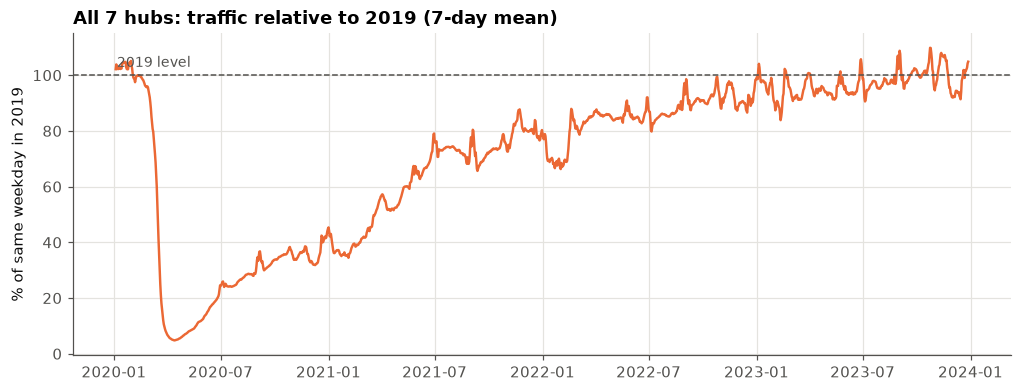

In [7]:
s, _ = load_series("ALL7")
base = s["2019-01-01":"2019-12-31"]
ratio = {}
for k, yr in [(1, "2020"), (2, "2021"), (3, "2022"), (4, "2023")]:
    cur = s[yr]
    ref = s.shift(364 * k)[yr]
    ratio[yr] = 100 * cur / ref
r = pd.concat(ratio.values()).rolling(7, center=True).mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(r.index, r, color=COL["AR-Holt"])
ax.axhline(100, color=MUTED, lw=1, ls="--")
ax.text(r.index[5], 103, "2019 level", color=MUTED, fontsize=9)
ax.set_ylabel("% of same weekday in 2019")
ax.set_title("All 7 hubs: traffic relative to 2019 (7-day mean)", loc="left")
save(fig, "03_covid_collapse")
low_day = r.idxmin()
print(f"Lowest 7-day average: {r.min():.1f}% of 2019 on {low_day.date()}")
for yr in ["2020", "2021", "2022", "2023"]:
    print(f"  mean for {yr}: {r[yr].mean():5.1f}% of 2019")
first_back = r[low_day:][r[low_day:] >= 95].index.min()
print("First day after the low that the 7-day mean was back to ≥95% of 2019:", first_back.date() if pd.notna(first_back) else "never")

### 4.4 Hourly profile
Share of a day's passengers in each hour (most recent 52 weeks), used later by the staffing
planner. The table below lists each airport's single busiest weekday-hour.

,weekday,hour,share_pct
airport,,,
ATL,Sat,7,8.402
DEN,Tue,8,8.918
DFW,Sat,6,8.201
JFK,Tue,15,6.875
LAX,Sat,7,7.903
ORD,Sat,6,8.647
SEA,Sat,9,8.172


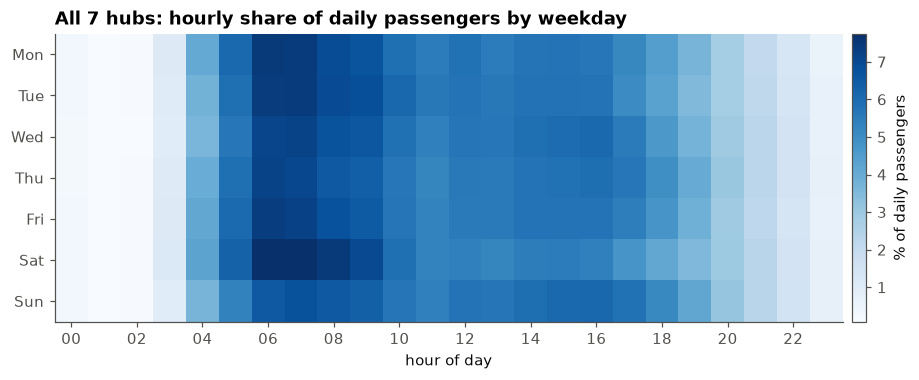

In [8]:
prof = load_hourly_profile()
p = prof[prof.airport == "ALL7"].pivot(index="weekday", columns="hour", values="share")
p.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(100 * p.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), p.index)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("hour of day")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("% of daily passengers")
ax.set_title("All 7 hubs: hourly share of daily passengers by weekday", loc="left")
save(fig, "04_hourly_profile")
peak = prof[prof.airport != "ALL7"].loc[lambda d: d.groupby("airport")["share"].idxmax()]
display(peak.assign(share_pct=lambda d: 100 * d.share).drop(columns="share")
        .assign(weekday=lambda d: d.weekday.map(dict(enumerate(p.index)))).set_index("airport"))

## 5. Decomposition

**STL** (Seasonal-Trend decomposition using LOESS) on the daily ALL7 series with period 7
and robust weights, so holiday spikes end up in the remainder instead of distorting the
trend. We show the last two years for readability. **Classical multiplicative**
decomposition on AirPassengers shows a seasonal amplitude that grows with the level — the
reason we use *multiplicative* seasonal indices.

Strength of weekly seasonality  F_S = 0.659
Strength of trend               F_T = 0.973


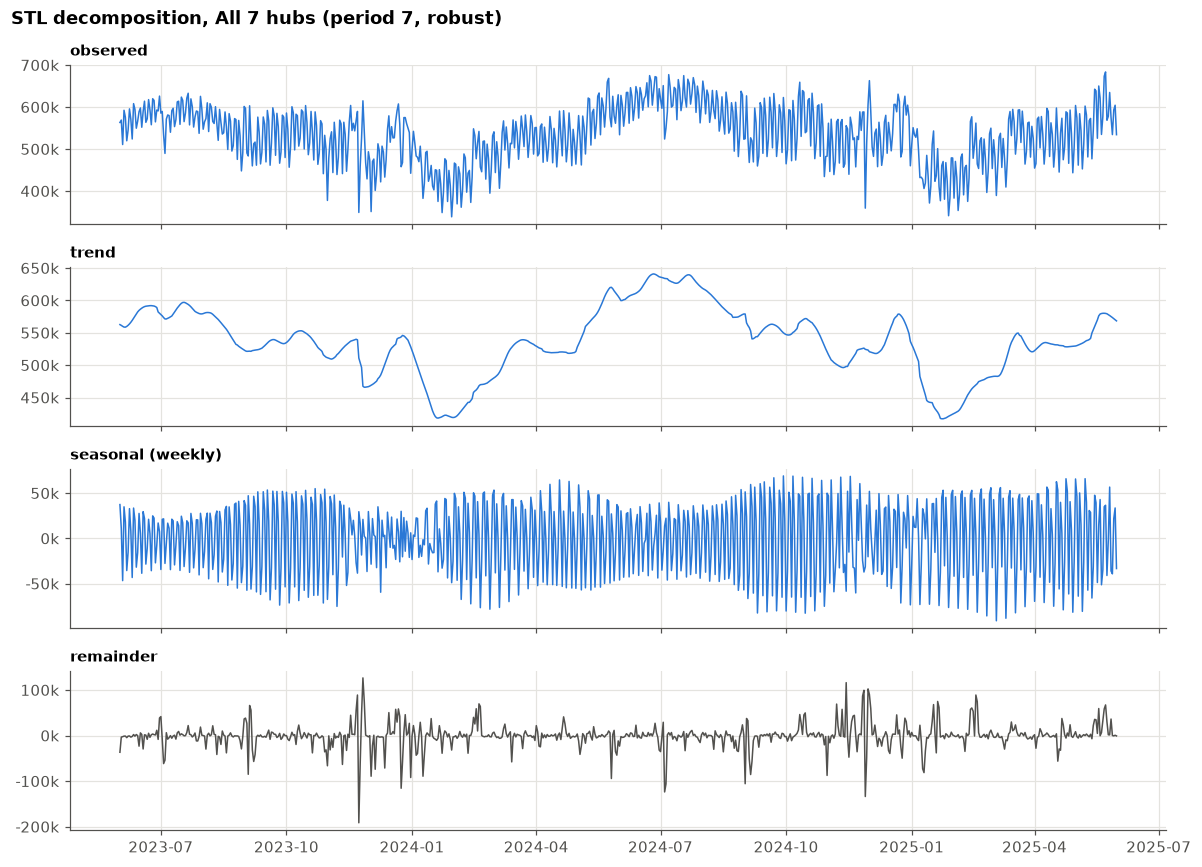

In [9]:
from statsmodels.tsa.seasonal import STL, seasonal_decompose
s, _ = load_series("ALL7")
stl = STL(s, period=7, robust=True).fit()
part = slice("2023-06-01", "2025-05-31")
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, (name, comp) in zip(axes, [("observed", s), ("trend", stl.trend), ("seasonal (weekly)", stl.seasonal), ("remainder", stl.resid)]):
    ax.plot(comp[part].index, comp[part], color=COL["Holt"] if name != "remainder" else MUTED, lw=1)
    ax.set_title(name, loc="left", fontsize=10)
    thousands(ax)
fig.suptitle("STL decomposition, All 7 hubs (period 7, robust)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "05_stl_all7")
var_r = stl.resid.var()
print(f"Strength of weekly seasonality  F_S = {max(0, 1 - var_r / (stl.seasonal + stl.resid).var()):.3f}")
print(f"Strength of trend               F_T = {max(0, 1 - var_r / (stl.trend + stl.resid).var()):.3f}")

Monthly seasonal indices:
date
Jan    0.910
Feb    0.884
Mar    1.007
Apr    0.976
May    0.981
Jun    1.113
Jul    1.227
Aug    1.220
Sep    1.060
Oct    0.922
Nov    0.801
Dec    0.899


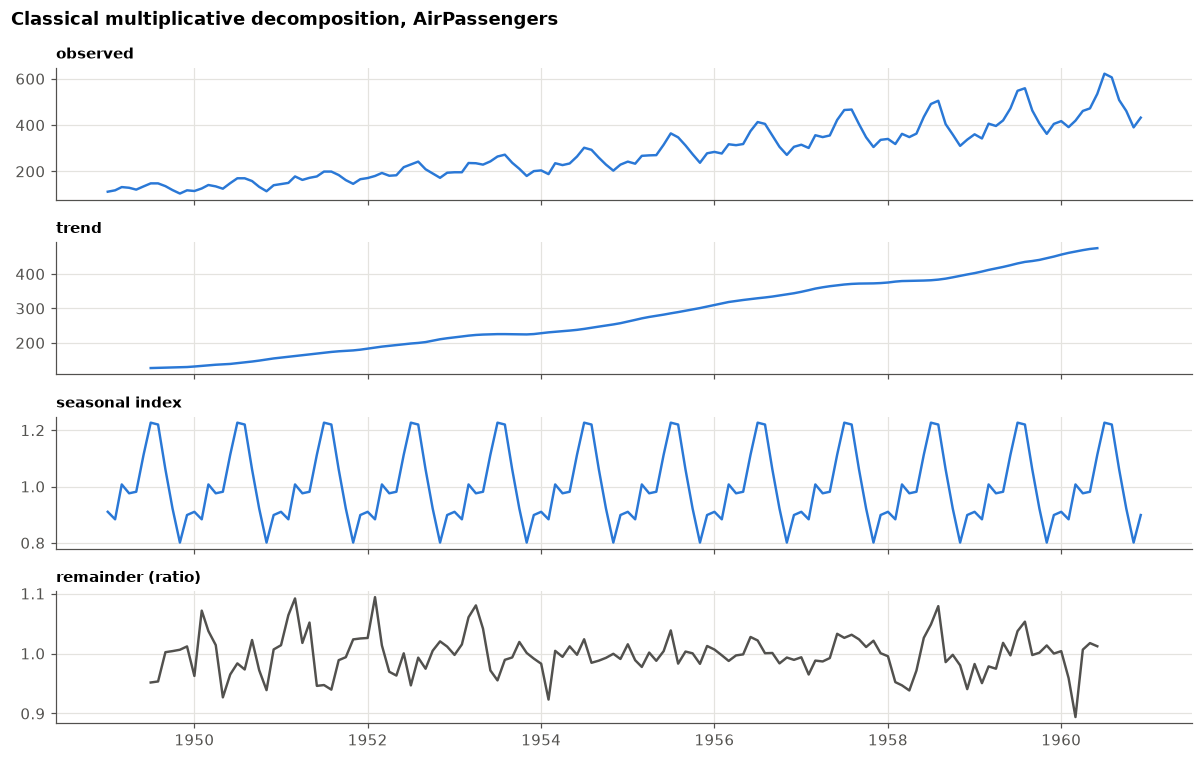

In [10]:
dec = seasonal_decompose(ap, model="multiplicative", period=12)
fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
for ax, (name, comp) in zip(axes, [("observed", dec.observed), ("trend", dec.trend), ("seasonal index", dec.seasonal), ("remainder (ratio)", dec.resid)]):
    ax.plot(comp.index, comp, color=COL["Holt"] if "remainder" not in name else MUTED)
    ax.set_title(name, loc="left", fontsize=10)
fig.suptitle("Classical multiplicative decomposition, AirPassengers", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "06_airpassengers_decomposition")
si = dec.seasonal[:12]
si.index = si.index.month_name().str[:3]
print("Monthly seasonal indices:"); print(si.round(3).to_string())

## 6. Stationarity

We run two complementary tests:

* **ADF** (Augmented Dickey–Fuller): $H_0$ = unit root (non-stationary). Small p ⇒ stationary.
* **KPSS**: $H_0$ = (level-)stationary. Small p ⇒ non-stationary.

They agree when ADF rejects and KPSS does not (stationary), or vice versa. (KPSS p-values
are reported by statsmodels only inside [0.01, 0.10]; values at the edge mean "at most" /
"at least".)

In [11]:
from statsmodels.tsa.stattools import adfuller, kpss

def tests(x, name):
    x = pd.Series(x).dropna()
    adf_stat, adf_p = adfuller(x, autolag="AIC")[:2]
    with warnings.catch_warnings():  # KPSS warns when p is outside its table
        warnings.simplefilter("ignore")
        kpss_stat, kpss_p = kpss(x, regression="c", nlags="auto")[:2]
    adf_says = "stationary" if adf_p < 0.05 else "unit root"
    kpss_says = "non-stationary" if kpss_p < 0.05 else "stationary"
    if adf_says == "stationary" and kpss_says == "stationary":
        verdict = "stationary (both agree)"
    elif adf_says == "unit root" and kpss_says == "non-stationary":
        verdict = "non-stationary (both agree)"
    else:
        verdict = "inconclusive / trend- or difference-stationary"
    return {"series": name, "ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kpss_stat,
            "KPSS p": kpss_p, "verdict": verdict}

s, _ = load_series("ALL7")
rows = [tests(s, "ALL7 raw"), tests(np.log(s), "ALL7 log"), tests(np.log(s).diff(), "ALL7 Δ log"),
        tests(np.log(s).diff(7), "ALL7 Δ7 log (weekly diff)"),
        tests(ap, "AirPassengers raw"), tests(np.log(ap), "AirPassengers log"),
        tests(np.log(ap).diff(), "AirPassengers Δ log"), tests(np.log(ap).diff().diff(12), "AirPassengers Δ Δ12 log")]
stat_tab = pd.DataFrame(rows).set_index("series")
display(stat_tab.style.format({"ADF stat": "{:.2f}", "ADF p": "{:.4f}", "KPSS stat": "{:.3f}", "KPSS p": "{:.3f}"}))

,ADF stat,ADF p,KPSS stat,KPSS p,verdict
series,,,,,
ALL7 raw,-1.58,0.4950,2.271,0.010,non-stationary (both agree)
ALL7 log,-2.44,0.1318,1.859,0.010,non-stationary (both agree)
ALL7 Δ log,-8.26,0.0000,0.053,0.100,stationary (both agree)
ALL7 Δ7 log (weekly diff),-7.65,0.0000,0.053,0.100,stationary (both agree)
AirPassengers raw,0.82,0.9919,1.651,0.010,non-stationary (both agree)
AirPassengers log,-1.72,0.4224,1.669,0.010,non-stationary (both agree)
AirPassengers Δ log,-2.72,0.0711,0.038,0.100,inconclusive / trend- or difference-stationary
AirPassengers Δ Δ12 log,-4.44,0.0002,0.073,0.100,stationary (both agree)


**Interpretation.** The levels (raw and log) of both series are not stationary — the trend and
the COVID break move the mean. For the daily series one difference is enough; for monthly
AirPassengers the first difference is still inconclusive because of the strong yearly pattern,
and a further seasonal difference is needed. This is why a
**trend** model (Holt) — which forecasts the *change* via $b_t$ — is natural here, rather
than a model that assumes a constant mean. The ACF/PACF of the differenced log series below
show strong spikes at lags 7, 14, 21, … — the weekly seasonality we remove with seasonal
indices before applying Holt.

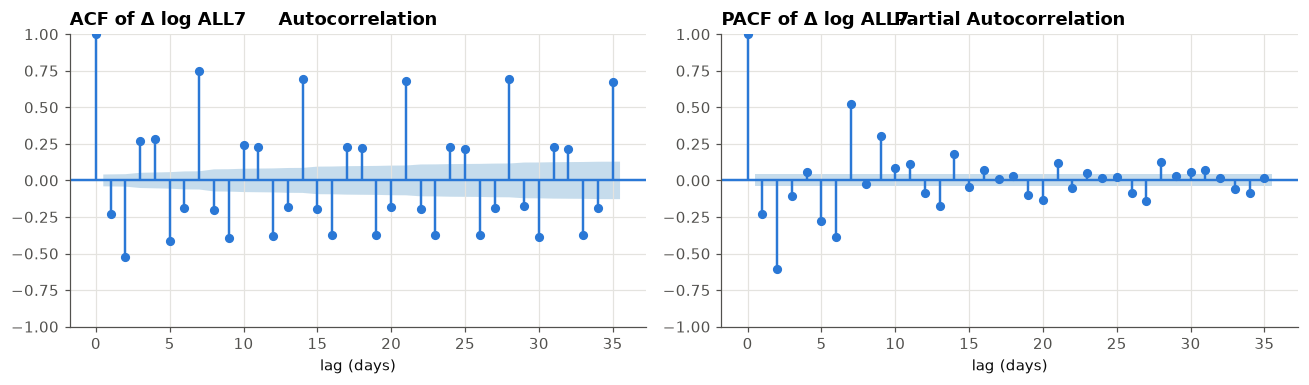

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
x = np.log(s).diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(x, lags=35, ax=axes[0], color=COL["Holt"], vlines_kwargs={"colors": COL["Holt"]})
plot_pacf(x, lags=35, ax=axes[1], method="ywm", color=COL["Holt"], vlines_kwargs={"colors": COL["Holt"]})
axes[0].set_title("ACF of Δ log ALL7", loc="left"); axes[1].set_title("PACF of Δ log ALL7", loc="left")
for ax in axes:
    ax.set_xlabel("lag (days)")
fig.tight_layout()
save(fig, "07_acf_pacf")

## 7. Theory: from SES to AR-Holt

**Seasonal adjustment first.** Holt's method has no seasonal term, so we model a seasonally
adjusted series. The multiplicative index of season position $j$ (weekday or month) is the
**median** of $y_t / \text{CMA}_t$ over a window, normalised to mean 1. Two versions are compared:

* **v1 — fixed indices:** one index set $s_j$, estimated on the last 26 training weeks (all training
  data for monthly series) and used for every later date:
  $x_t = y_t / s_{j(t)}$, $\ \hat y_{t+h|t} = \hat x_{t+h|t}\, s_{j(t+h)}$.
* **v2 — rolling indices (default):** the index set is re-estimated at **every** time step $t$ from
  the 26 weeks ending at $t$ only (monthly: all data up to $t$), giving $S_{t,j}$. Observation $t$ is
  adjusted with the indices known on day $t$, and a forecast made at origin $t$ is re-seasonalised
  with the indices estimated at $t$:
  $$x_t = y_t / S_{t,\,j(t)}, \qquad \hat y_{t+h|t} = \hat x_{t+h|t}\; S_{t,\,j(t+h)} .$$
  No data after the origin is used (unit-tested), the same rule applies to every seasonally adjusted
  model (SES, Holt, damped Holt, Trigg–Leach, AR-Holt), and at the first test origin v1 and v2
  use identical indices. Holt–Winters and the naive models work on the raw series and are unaffected.

### 7.1 Simple exponential smoothing (SES)
$$\ell_t = \alpha x_t + (1-\alpha)\,\ell_{t-1}, \qquad \hat x_{t+h|t} = \ell_t$$
A weighted average with geometrically decaying weights. Flat forecasts — **no trend**.

### 7.2 Holt's linear trend method (Holt 1957)
$$\ell_t = \alpha x_t + (1-\alpha)(\ell_{t-1}+b_{t-1})$$
$$b_t = \beta(\ell_t-\ell_{t-1}) + (1-\beta)\,b_{t-1}$$
$$\hat x_{t+h|t} = \ell_t + h\,b_t$$
*Added:* a trend $b_t$. *Problem:* the trend is extrapolated forever — after a collapse,
Holt projects the collapse further (forecasts can even go negative).

### 7.3 Damped trend (Gardner & McKenzie 1985)
$$\ell_t = \alpha x_t + (1-\alpha)(\ell_{t-1}+\phi b_{t-1}), \quad b_t = \beta(\ell_t-\ell_{t-1}) + (1-\beta)\phi\, b_{t-1}$$
$$\hat x_{t+h|t} = \ell_t + (\phi+\phi^2+\dots+\phi^h)\, b_t, \qquad \phi\in[0.80, 1]$$
*Added:* $\phi<1$ makes the trend fade, so long-horizon forecasts flatten. Empirically one of
the most robust exponential-smoothing variants.

**Error-correction form.** With the one-step forecast $\hat x_t = \ell_{t-1}+\phi b_{t-1}$ and
error $e_t = x_t - \hat x_t$, damped Holt is equivalently
$$\ell_t = \hat x_t + \alpha e_t, \qquad b_t = \phi b_{t-1} + \alpha\beta\, e_t .$$
This form makes it obvious *where* to intervene: the step size $\alpha$ and the error $e_t$.

### 7.4 Adaptive response rate (Trigg & Leach 1967)
Smoothed error and smoothed absolute error give a **tracking signal**:
$$E_t = \gamma e_t + (1-\gamma)E_{t-1}, \quad M_t = \gamma|e_t| + (1-\gamma)M_{t-1}, \quad TS_t = E_t/M_t \in[-1,1]$$
$|TS_t|\approx 0$ when errors alternate in sign (noise); $|TS_t|\to 1$ when errors are
persistently one-signed (the model is biased — a shift). ARR sets $\alpha_t = |TS_{t-1}|$
(clipped to [0.05, 0.95]). *Problem:* $\alpha_t$ jumps around and is very noisy; one big
holiday error both moves the level and inflates $TS$.

### 7.5 AR-Holt — the proposed Adaptive Robust Holt
AR-Holt combines four published ideas: the tracking signal (Trigg & Leach 1967), a *smooth*
transition between parameter regimes (Taylor 2004), Huber-type robust cleaning of errors
(Gelper, Fried & Croux 2010) and the damped trend (Gardner & McKenzie 1985). For $t=1,\dots,n$:

$$\hat x_t = \ell_{t-1} + \phi b_{t-1}, \qquad e_t = x_t - \hat x_t$$

$$\text{regime}_t = \begin{cases}\text{shock} & |TS_{t-1}| \ge \tau\\ \text{calm} & \text{otherwise}\end{cases}
\qquad
\tilde e_t = \begin{cases} e_t & \text{shock}\\ \sigma_{t-1}\,\psi_k\!\left(e_t/\sigma_{t-1}\right) & \text{calm}\end{cases},\quad \psi_k(z)=\max(-k,\min(k,z))$$

$$\alpha_t = \operatorname{expit}\!\big(a + b\,|TS_{t-1}|\big) = \frac{1}{1+e^{-(a+b|TS_{t-1}|)}}$$

$$\ell_t = \hat x_t + \alpha_t\tilde e_t, \qquad b_t = \phi b_{t-1} + \alpha_t\beta\,\tilde e_t$$

$$\sigma_t = \lambda|\tilde e_t| + (1-\lambda)\sigma_{t-1}$$

$$E_t = \gamma\tilde e_t+(1-\gamma)E_{t-1},\quad M_t = \gamma|\tilde e_t|+(1-\gamma)M_{t-1},\quad TS_t = E_t/M_t$$

Forecast: $\hat x_{n+h} = \ell_n + (\phi+\dots+\phi^h)\,b_n$.

**What each piece does.**
* **Smooth transition** — calm $\alpha = \operatorname{expit}(a)$; as $|TS|\to1$, $\alpha\to\operatorname{expit}(a+b)$.
  $b\ge0$ guarantees $\alpha$ can only *rise* under bias. Unlike ARR, $\alpha_t$ is a smooth
  function with two fitted parameters, so it is stable in calm periods.
* **Robust clipping (calm only)** — an isolated error larger than $k\sigma$ (e.g. Thanksgiving)
  moves the level by at most $\alpha k\sigma$; such points are flagged as outliers.
* **Regime switch** — if errors stay one-signed, $|TS|$ crosses $\tau$ after a few steps,
  clipping is switched **off** and the full error is used: a persistent shift is *not* an outlier.
  The clipped errors also feed $TS$, so a single outlier cannot trigger the shock regime by itself.
* **Running scale $\sigma_t$** — sets the clipping threshold and makes the prediction intervals
  widen automatically after shocks (Section 12).

**Parameters.** Fitted by minimising the one-step-ahead SSE after a burn-in of $2m$ points
(Nelder–Mead, 3 starting points, parameters mapped through logit/softplus so the
constraints always hold): $a\in\mathbb R$, $b\ge0$ (softplus), $\beta\in(0,1)$ (logit),
$\phi\in[0.80,1]$. Fixed a-priori (not tuned on the test data):
$\gamma=0.15,\ k=2.5,\ \lambda=0.1,\ \tau=0.5$.

*Interpretation note:* the build specification lists "$a, b \ge 0$". We constrain only $b$:
forcing $a\ge0$ would force calm $\alpha \ge 0.5$, i.e. a nervous model in normal times, which
contradicts the purpose of the calm regime. $a$ is therefore unconstrained.

**Initialisation** (all smoothing models): $\ell_0 = \bar x_{1..m}$,
$b_0 = (\bar x_{m+1..2m}-\bar x_{1..m})/m$, $\sigma_0 = 1.4826\cdot\text{MAD}(\Delta x_{1..2m})$,
$E_0=0$, $M_0=\sigma_0$, $TS_0=0$; $m=7$ (daily), 12 (monthly), 3 (annual).

**Nesting.** With $b=0$ and $k=\infty$, $\alpha_t\equiv\operatorname{expit}(a)$ and no error is
ever clipped, so AR-Holt *is exactly* damped Holt (verified to machine precision in
`tests/test_models.py::test_ar_holt_nests_damped_holt`). AR-Holt can therefore never be
*structurally* worse than damped Holt in-sample; it only adds flexibility.

**Prediction intervals — locally-adaptive split conformal.** For the last $N$ training origins
($N=365$ daily, 36 monthly, all for annual) compute standardised $h$-step errors
$z_{t,h} = (x_{t+h}-\hat x_{t+h|t})/\sigma_t$, take their empirical quantiles $q_h$
(10%/90% for 80%, 2.5%/97.5% for 95%), and set the interval
$\big(\hat x_{n+h} + q_h\sigma_n\big)\, s_{j(n+h)}$. No normality assumption; width scales with
the current $\sigma_n$. Other models use an EWMA ($\lambda=0.1$) of their own absolute
one-step errors as $\sigma_t$.

## 8. Implementation check: from-scratch Holt vs statsmodels

Our Holt is written from scratch in numpy. We check it against statsmodels' `Holt` on the
FPP3 textbook example (Australian air passengers), with the same initial states:

1. **Same parameters** — both run with our fitted $\alpha, \beta$: the fitted values and forecasts
   must be identical (pure recursion check).
2. **Each optimises its own parameters** — ours minimises SSE after a burn-in, statsmodels
   over all points, so small differences are expected.

In [13]:
from statsmodels.tsa.holtwinters import Holt as SMHolt
au_tr = au[:"2016"]
ours = Holt().fit(au_tr, freq="A")
x = au_tr.to_numpy()
sm_same = SMHolt(x, initialization_method="known", initial_level=ours.l0_, initial_trend=ours.b0_).fit(
    smoothing_level=ours.params_["alpha"], smoothing_trend=ours.params_["beta"], optimized=False)
sm_opt = SMHolt(x, initialization_method="known", initial_level=ours.l0_, initial_trend=ours.b0_).fit()
_, run = holt_filter(x, ours.params_["alpha"], ours.params_["beta"], 1.0, ours.l0_, ours.b0_)

years = [str(y) for y in range(2017, 2022)]
check = pd.DataFrame({
    "ours (from scratch)": ours.forecast(5)["mean"].to_numpy(),
    "statsmodels, same α β": np.asarray(sm_same.forecast(5)),
    "statsmodels, own α β": np.asarray(sm_opt.forecast(5))}, index=years)
display(check)
print(f"max |fitted ours − fitted statsmodels| (same parameters): {np.max(np.abs(run['xhat'] - sm_same.fittedvalues)):.2e}")
print(f"parameters  ours: α={ours.params_['alpha']:.4f} β={ours.params_['beta']:.4f}   "
      f"statsmodels: α={sm_opt.params['smoothing_level']:.4f} β={sm_opt.params['smoothing_trend']:.4f}")
print(f"max relative forecast difference (each optimised): "
      f"{np.max(np.abs(check.iloc[:, 0] - check.iloc[:, 2]) / check.iloc[:, 2]):.2%}")

,ours (from scratch),"statsmodels, same α β","statsmodels, own α β"
2017,74.743,74.743,74.737
2018,76.963,76.963,76.951
2019,79.182,79.182,79.164
2020,81.402,81.402,81.377
2021,83.622,83.622,83.590


max |fitted ours − fitted statsmodels| (same parameters): 7.11e-15
parameters  ours: α=0.8481 β=0.1144   statsmodels: α=0.8574 β=0.1121
max relative forecast difference (each optimised): 0.04%


## 9. Fitted parameters and their interpretation

Parameters of AR-Holt fitted on each training span (Experiment A: data up to 2024-05-31,
which *includes* COVID; Experiment B: data up to 2020-02-29, before COVID; C1/C2: classic
series). `alpha_calm` = expit(a), `alpha_shock` = expit(a + b) is the limit as |TS| → 1.

In [14]:
params = pd.read_csv(RES / "ar_holt_params.csv")
display(params.set_index(["experiment", "series"]).style.format("{:.3f}", subset=["a", "b", "beta", "phi", "alpha_calm", "alpha_shock"]))
pa = params[params.experiment.isin(["A", "B"])]
for e in ["A", "B"]:
    q = pa[pa.experiment == e]
    print(f"Exp {e}: median calm α = {q.alpha_calm.median():.3f}, median shock α = {q.alpha_shock.median():.3f}, "
          f"median φ = {q.phi.median():.3f}, median β = {q.beta.median():.4f}, "
          f"series with b ≈ 0 (no adaptivity learnt): {int((q.b < 0.05).sum())} of {len(q)}")

Exp A: median calm α = 0.333, median shock α = 0.620, median φ = 0.850, median β = 0.0000, series with b ≈ 0 (no adaptivity learnt): 1 of 8
Exp B: median calm α = 0.300, median shock α = 0.590, median φ = 0.878, median β = 0.0002, series with b ≈ 0 (no adaptivity learnt): 1 of 8


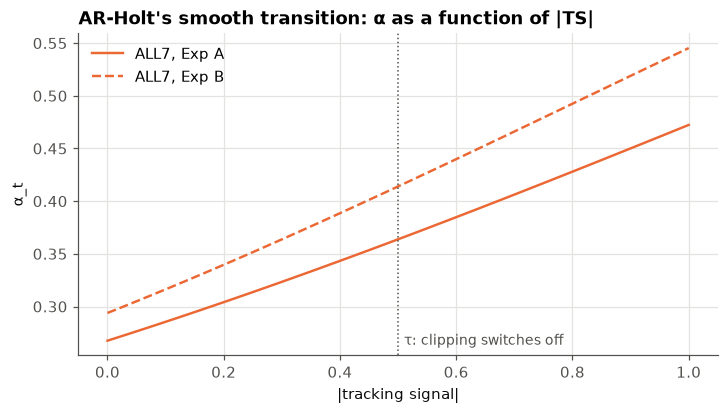

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ts = np.linspace(0, 1, 101)
from scipy.special import expit
for e, ls in [("A", "-"), ("B", "--")]:
    r = pa[(pa.experiment == e) & (pa.series == "ALL7")].iloc[0]
    ax.plot(ts, expit(r.a + r.b * ts), color=COL["AR-Holt"], ls=ls, label=f"ALL7, Exp {e}")
ax.axvline(config.AR_HOLT_HYPER["tau"], color=MUTED, lw=1, ls=":")
ax.text(config.AR_HOLT_HYPER["tau"] + 0.01, ax.get_ylim()[0] + 0.01, "τ: clipping switches off", color=MUTED, fontsize=9)
ax.set_xlabel("|tracking signal|"); ax.set_ylabel("α_t")
ax.set_title("AR-Holt's smooth transition: α as a function of |TS|", loc="left")
ax.legend()
save(fig, "08_alpha_transition")

**Reading the parameters.**
* **Calm α vs shock α.** Calm α is moderate — the model trusts a new observation only
  partially in normal times. As the tracking signal approaches 1 the step size rises towards
  the shock value, so the level catches up with a persistent shift much faster.
* **φ.** The damping parameter sits well below 1 for the airports: trends fade within days,
  which matches the mean-reverting behaviour of daily traffic around a slowly changing level.
* **β.** The trend smoothing is tiny: the daily trend changes slowly; most adaptation happens
  through the level.
* **b ≈ 0 on a few series** (counted above). There the one-step SSE gives no reason to raise α
  under bias, so the optimiser switches adaptivity off and AR-Holt falls back to a robust damped
  Holt. Adaptivity is *learnt from the training data*: a series whose history rewards a fast
  reaction to one-sided errors gets a large b; one where it does not gets b ≈ 0.
* **Annual data.** For the Australian series the optimum is α at its upper limit (each new year
  fully replaces the level) — the same answer as the textbook Holt fit — so AR-Holt has nothing
  to adapt.

## 10. How the model adapts: α_t and the tracking signal, 2019–2025 (key plot)

AR-Holt is fitted on the **full** ALL7 history. Shaded bands = shock regime (|TS| ≥ τ);
dots = outliers that were clipped while calm.

Full-history fit: calm α = 0.310, shock α = 0.481, β = 0.0000, φ = 0.872
Share of days in shock regime: 20.7%;  clipped outliers: 114


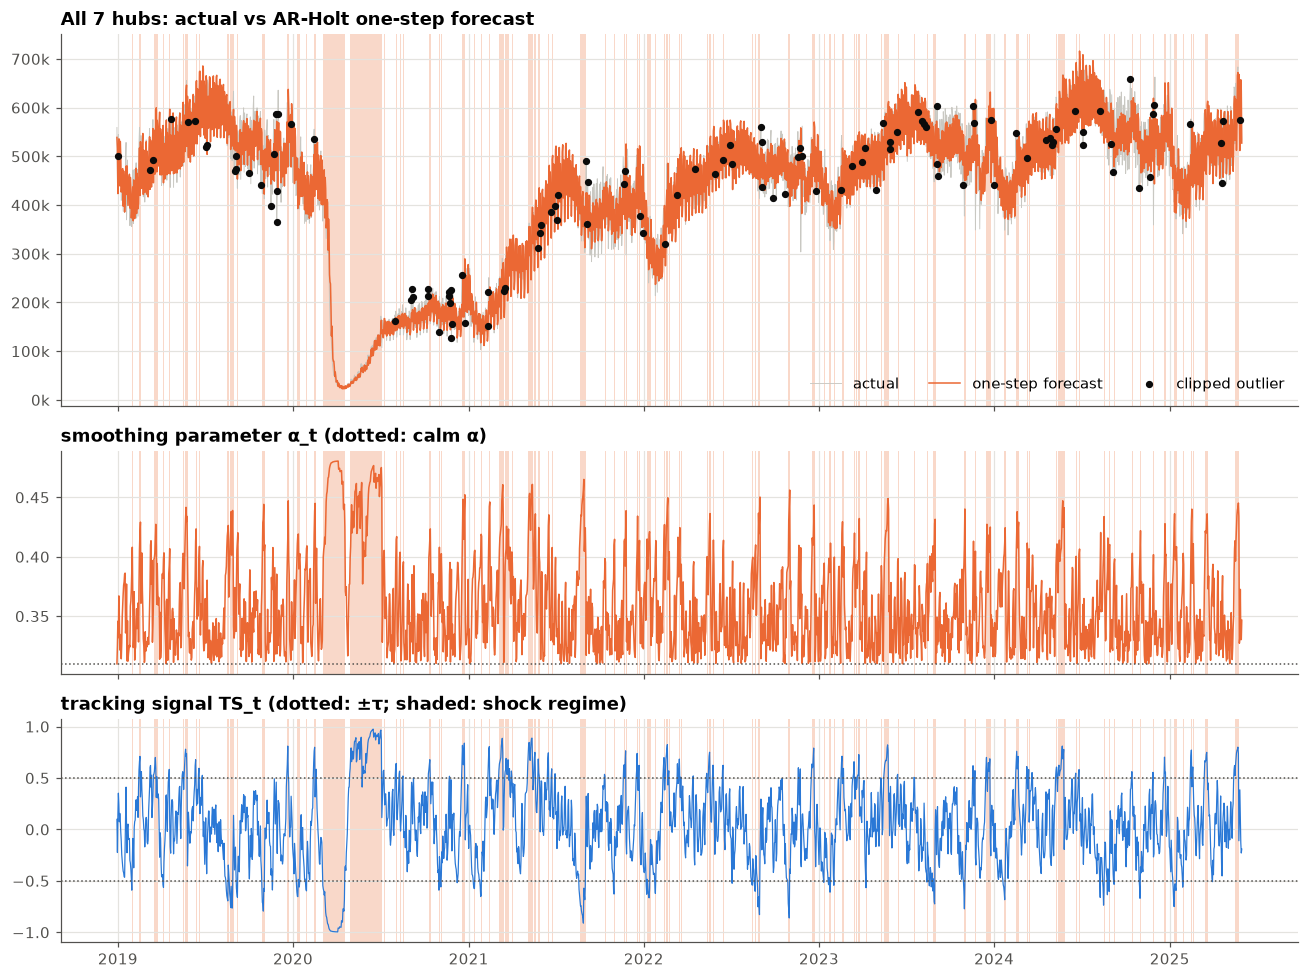

In [16]:
s, _ = load_series("ALL7")
ar_full = AdaptiveRobustHolt().fit(s, freq="D")
c = ar_full.components_
shock = c["regime"].eq("shock").to_numpy()

def shade(ax):
    runs, start = [], None
    for i, f in enumerate(shock):
        if f and start is None: start = i
        if not f and start is not None: runs.append((start, i - 1)); start = None
    if start is not None: runs.append((start, len(shock) - 1))
    for a_, b_ in runs:
        ax.axvspan(c.index[a_], c.index[b_] + pd.Timedelta(days=1), color=SHOCK_FILL, lw=0, zorder=0)

out = c[c.is_outlier]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, height_ratios=[2, 1.2, 1.2])
ax = axes[0]; shade(ax)
ax.plot(c.index, c.actual, color="#c9c8c2", lw=0.6, label="actual")
ax.plot(c.index, c.fitted, color=COL["AR-Holt"], lw=1.0, label="one-step forecast")
ax.scatter(out.index, out.actual, s=14, color=INK, zorder=3, label="clipped outlier")
ax.set_title("All 7 hubs: actual vs AR-Holt one-step forecast", loc="left"); thousands(ax)
ax.legend(loc="lower right", ncols=3)
ax = axes[1]; shade(ax)
ax.plot(c.index, c.alpha, color=COL["AR-Holt"], lw=1)
ax.axhline(ar_full.params_["alpha_calm"], color=MUTED, ls=":", lw=1)
ax.set_title("smoothing parameter α_t (dotted: calm α)", loc="left")
ax = axes[2]; shade(ax)
ax.plot(c.index, c.ts, color=COL["Holt"], lw=0.8)
for v in (config.AR_HOLT_HYPER["tau"], -config.AR_HOLT_HYPER["tau"]):
    ax.axhline(v, color=MUTED, ls=":", lw=1)
ax.set_title("tracking signal TS_t (dotted: ±τ; shaded: shock regime)", loc="left")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save(fig, "09_alpha_tracking_signal")
p = ar_full.params_
print(f"Full-history fit: calm α = {p['alpha_calm']:.3f}, shock α = {p['alpha_shock']:.3f}, β = {p['beta']:.4f}, φ = {p['phi']:.3f}")
print(f"Share of days in shock regime: {shock.mean():.1%};  clipped outliers: {int(c.is_outlier.sum())}")

### 10.1 Event table
Regime shifts (shock regime for ≥ 3 consecutive days) and outliers (isolated clipped days),
with a flag for days within ±2 days of a U.S. federal holiday (pandas
`USFederalHolidayCalendar`, which includes Thanksgiving). Below: the longest regime shifts,
then a summary.

In [17]:
ev = event_table(c)
display(ev[ev.type == "Regime shift"].sort_values("steps", ascending=False).head(8))
summary = ev.groupby("type").agg(events=("type", "size"), median_steps=("steps", "median"),
                                 share_near_holiday=("near_holiday", "mean"),
                                 median_abs_error_pct=("mean_error_pct", lambda v: v.abs().median()))
display(summary)

,start,end,type,steps,peak_alpha,mean_error_pct,near_holiday
26,2020-03-04,2020-04-18,Regime shift,46,0.481,-11.9,False
28,2020-05-26,2020-07-04,Regime shift,40,0.477,4.3,True
27,2020-04-29,2020-05-24,Regime shift,26,0.462,5.8,True
56,2021-08-20,2021-09-02,Regime shift,14,0.465,-1.1,False
123,2024-05-14,2024-05-26,Regime shift,13,0.447,0.4,True
46,2021-05-05,2021-05-15,Regime shift,11,0.461,2.9,False
141,2025-05-16,2025-05-25,Regime shift,10,0.445,0.6,True
96,2023-05-17,2023-05-26,Regime shift,10,0.449,1.2,False


,events,median_steps,share_near_holiday,median_abs_error_pct
type,,,,
Outlier,87,1.0,0.425,13.0
Regime shift,56,4.0,0.339,1.5


### 10.2 Are the known events detected?
We check the events listed in the data description against the event tables of the series
where they happened (each airport fitted on its own full history).

In [18]:
checks = [("COVID collapse", "ALL7", "2020-03-15"), ("COVID collapse", "ATL", "2020-03-20"),
          ("Winter storm (Texas)", "DFW", "2021-02-17"), ("Blizzard", "DEN", "2021-03-14"),
          ("Nor'easter", "JFK", "2021-02-01"), ("Blizzard", "JFK", "2022-01-29")]
for yr, day in [(2021, "11-25"), (2022, "11-24"), (2023, "11-23"), (2024, "11-28")]:
    checks.append((f"Thanksgiving {yr}", "ALL7", f"{yr}-{day}"))
fits = {}
rows = []
for what, series, day in checks:
    if series not in fits:
        y_, _ = load_series(series)
        m_ = AdaptiveRobustHolt().fit(y_, freq="D")
        fits[series] = (m_.components_, event_table(m_.components_))
    comp, evs = fits[series]
    d = pd.Timestamp(day)
    starts, ends = pd.to_datetime(evs.start), pd.to_datetime(evs.end)
    near = evs[(starts <= d + pd.Timedelta(days=2)) & (ends >= d - pd.Timedelta(days=2))]
    rows.append({"event": what, "series": series, "date": day,
                 "detected as": ", ".join(sorted(set(near.type))) or "—",
                 "regime on the day": comp.loc[d, "regime"], "α on the day": comp.loc[d, "alpha"],
                 "one-step error %": 100 * comp.loc[d, "error"] / (comp.loc[d, "adjusted"] - comp.loc[d, "error"])})
display(pd.DataFrame(rows).style.format({"α on the day": "{:.3f}", "one-step error %": "{:+.1f}"}))

,event,series,date,detected as,regime on the day,α on the day,one-step error %
0,COVID collapse,ALL7,2020-03-15,Regime shift,shock,0.467,-12.7
1,COVID collapse,ATL,2020-03-20,Regime shift,shock,0.351,-36.1
2,Winter storm (Texas),DFW,2021-02-17,Outlier,calm,0.294,-43.5
3,Blizzard,DEN,2021-03-14,Outlier,calm,0.320,-95.5
4,Nor'easter,JFK,2021-02-01,Outlier,calm,0.720,-86.3
5,Blizzard,JFK,2022-01-29,Outlier,calm,0.746,-92.4
6,Thanksgiving 2021,ALL7,2021-11-25,Outlier,shock,0.439,-43.3
7,Thanksgiving 2022,ALL7,2022-11-24,Outlier,shock,0.408,-45.6
8,Thanksgiving 2023,ALL7,2023-11-23,Outlier,shock,0.405,-43.4
9,Thanksgiving 2024,ALL7,2024-11-28,Outlier,shock,0.402,-42.0


**Discussion.** The COVID collapse appears as a long *regime shift* — exactly what the design
intends: clipping switched off and α raised for weeks. The storm days appear as one-day
*outliers* in the calm regime: their errors were clipped, so the level was protected from them.

**Thanksgiving is more subtle.** It is a multi-day pattern: busy Tuesday/Wednesday, a deep dip on
Thursday, a busy Sunday after. The run-up days produce several same-signed errors, which push the
tracking signal over τ, so on Thanksgiving Day itself the model is already in the *shock* regime
and the dip is **not** clipped (the neighbouring days are flagged as outliers). In other words,
holiday weeks are partly mistaken for short shifts — a concrete argument for explicit holiday
effects (future work). The event tables also show the model's
honest weakness: in the noisier post-COVID years many short (3–5 day) shock runs appear. Their
average error is small — they are the tracking signal reacting to ordinary week-to-week drift,
when |TS| briefly exceeds τ = 0.5. They are harmless for accuracy (α rises only modestly) but
they mean that "regime shift" in this table should be read as "the model sped up", not
necessarily as a real-world event.

### 10.3 Robustness of the fixed hyperparameters (validation window only)
γ, k, λ, τ were fixed *a priori* and **not tuned**. To show that the results do not hinge on
them, we vary τ and k on a validation window *inside the Experiment A training data*: fit on
data up to 2023-12-02, evaluate one-step and 7-step forecasts over the last 26 weeks of
training (2023-12-03 → 2024-05-31). The test year is never touched.

In [19]:
from airdemand.evaluation import backtest_model
s, _ = load_series("ALL7")
val_train_end, val_end = "2023-12-02", "2024-05-31"
rows = []
for tau_ in (0.3, 0.5, 0.7):
    for k_ in (2.0, 2.5, 3.0, np.inf):
        m_ = AdaptiveRobustHolt(tau=tau_, k=k_).fit(s[:val_train_end], freq="D")
        fc_ = backtest_model(m_, s[:val_end], val_train_end, 7)
        ape = (fc_.actual - fc_["mean"]).abs() / fc_.actual * 100
        rows.append({"tau": tau_, "k": k_, "MAPE h=1": ape[fc_.h == 1].mean(), "MAPE h=7": ape[fc_.h == 7].mean()})
sens = pd.DataFrame(rows)
display(sens.pivot(index="tau", columns="k", values="MAPE h=1").style.format("{:.2f}").set_caption("validation MAPE, h=1"))
display(sens.pivot(index="tau", columns="k", values="MAPE h=7").style.format("{:.2f}").set_caption("validation MAPE, h=7"))
d = sens[(sens.tau == 0.5) & (sens.k == 2.5)].iloc[0]
print(f"default (τ=0.5, k=2.5): h=1 {d['MAPE h=1']:.2f}%, h=7 {d['MAPE h=7']:.2f}%;  "
      f"range over grid: h=1 {sens['MAPE h=1'].min():.2f}–{sens['MAPE h=1'].max():.2f}%, "
      f"h=7 {sens['MAPE h=7'].min():.2f}–{sens['MAPE h=7'].max():.2f}%")

k,2.000000,2.500000,3.000000,inf
tau,,,,
0.300000,4.89,4.88,4.93,4.92
0.500000,4.90,4.91,4.90,4.92
0.700000,4.90,4.93,4.93,4.92


k,2.000000,2.500000,3.000000,inf
tau,,,,
0.300000,6.46,6.43,6.60,6.57
0.500000,6.51,6.50,6.49,6.57
0.700000,6.58,6.64,6.57,6.57


default (τ=0.5, k=2.5): h=1 4.91%, h=7 6.50%;  range over grid: h=1 4.88–4.93%, h=7 6.43–6.64%


### 10.4 Sudden versus gradual shocks (synthetic experiment)
A controlled experiment shows *when* adaptivity pays off. We simulate 500 days with a few
earlier level steps and holiday-like outliers, fit both models on the first 400 days, then roll
through an **unseen −60% shock** with parameters fixed. The shock is either instantaneous or
spread over 7 or 14 days (COVID-like). We count in how many of 10 random seeds AR-Holt has the
lower mean absolute one-step error over the 30 days after the shock starts.

In [20]:
def synthetic(seed, ramp):
    rng = np.random.default_rng(seed)
    n = 500
    lvl = np.full(n, 10_000.0); lvl[100:] *= 1.25; lvl[220:] *= 0.70; lvl[330:] *= 1.20
    drop = np.ones(n); drop[400:] = 0.4
    if ramp > 1:
        drop[400:400 + ramp] = np.linspace(1, 0.4, ramp + 1)[1:]
    y = lvl * drop * (1 + rng.normal(0, 0.02, n))
    spikes = rng.choice(np.r_[10:395, 440:500], 15, replace=False)
    y[spikes] *= rng.choice([0.6, 1.35], 15)
    return pd.Series(y, index=pd.date_range("2022-01-01", periods=n, freq="D"))

def mae_window(model, y, a, b):
    p_ = model.paths(y, 1)
    return np.abs(p_["x"][a + 1:b + 1] - p_["adj"][a:b, 0]).mean()

rows = []
for label, ramp, (a, b) in [("instant drop, days 1–30", 1, (400, 430)), ("instant drop, days 4–30", 1, (403, 430)),
                            ("7-day decline, days 1–30", 7, (400, 430)), ("14-day decline, days 1–30", 14, (400, 430))]:
    wins, ratio = 0, []
    for seed in range(10):
        y_ = synthetic(seed, ramp)
        h_ = Holt().fit(y_.iloc[:400], freq="D"); r_ = AdaptiveRobustHolt().fit(y_.iloc[:400], freq="D")
        e_h, e_r = mae_window(h_, y_, a, b), mae_window(r_, y_, a, b)
        wins += e_r < e_h; ratio.append(e_r / e_h)
    rows.append({"scenario": label, "AR-Holt wins (of 10)": wins, "median MAE ratio AR/Holt": np.median(ratio)})
display(pd.DataFrame(rows).set_index("scenario").style.format({"median MAE ratio AR/Holt": "{:.2f}"}))

,AR-Holt wins (of 10),median MAE ratio AR/Holt
scenario,,
"instant drop, days 1–30",4,1.03
"instant drop, days 4–30",9,0.54
"7-day decline, days 1–30",10,0.46
"14-day decline, days 1–30",10,0.37


**Interpretation — an honest trade-off.** On the first day of an *instantaneous* drop AR-Holt
cannot know whether it is facing an outlier or a shift, so it clips the error and waits until the
tracking signal confirms the shift (about 2–3 steps). Holt moves immediately. Over the very first
days AR-Holt therefore loses; once the shift is confirmed, it re-levels much faster. For
*gradual* collapses — which is how COVID actually unfolded at airports — AR-Holt wins clearly.

## 11. Residual diagnostics

One-step residuals of AR-Holt fitted on the Experiment A training data, expressed as % of the
forecast, for the post-COVID part of the training span (2022-06-01 → 2024-05-31) so the
collapse does not dominate. A well-specified model should leave white-noise residuals.

,Ljung–Box Q,p-value
7,154.3,5e-30
14,164.4,9.3e-28
28,184.3,6.2e-25


residual mean +0.15%, sd 6.48%, skewness -0.84, excess kurtosis 7.45
Jarque–Bera normality test: statistic 1777, p = 0


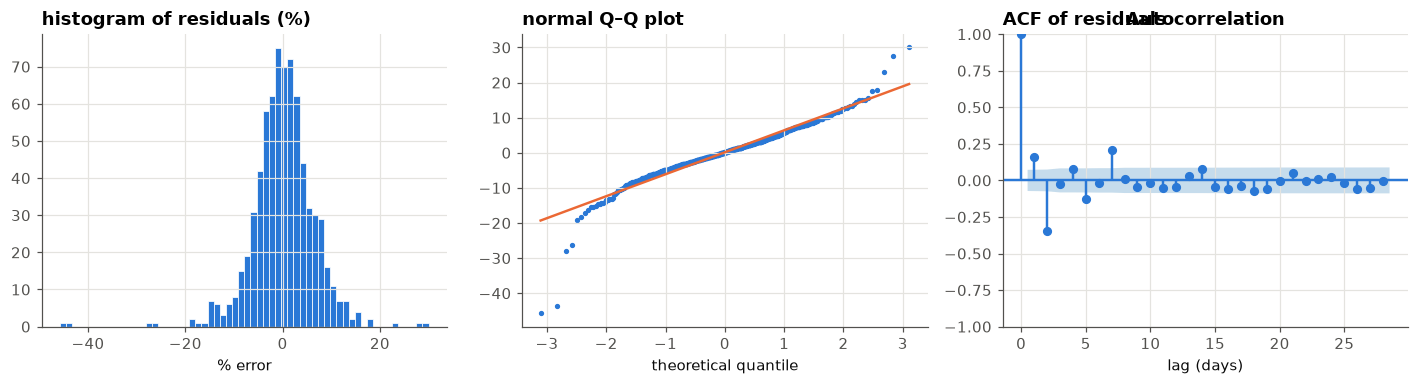

In [21]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats as sst
s, _ = load_series("ALL7")
ar_a = AdaptiveRobustHolt().fit(s[:"2024-05-31"], freq="D")
ca = ar_a.components_["2022-06-01":"2024-05-31"]
resid_pct = 100 * ca["error"] / (ca["adjusted"] - ca["error"])
lb = acorr_ljungbox(resid_pct, lags=[7, 14, 28], return_df=True)
display(lb.rename(columns={"lb_stat": "Ljung–Box Q", "lb_pvalue": "p-value"}).style.format({"Ljung–Box Q": "{:.1f}", "p-value": "{:.2g}"}))
print(f"residual mean {resid_pct.mean():+.2f}%, sd {resid_pct.std():.2f}%, skewness {sst.skew(resid_pct):.2f}, "
      f"excess kurtosis {sst.kurtosis(resid_pct):.2f}")
jb = sst.jarque_bera(resid_pct)
print(f"Jarque–Bera normality test: statistic {jb.statistic:.0f}, p = {jb.pvalue:.2g}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(resid_pct, bins=60, color=COL["Holt"], edgecolor="white", linewidth=0.5)
axes[0].set_title("histogram of residuals (%)", loc="left"); axes[0].set_xlabel("% error")
(osm, osr), (slope, icpt, _) = sst.probplot(resid_pct, dist="norm")
axes[1].scatter(osm, osr, s=6, color=COL["Holt"]); axes[1].plot(osm, slope * osm + icpt, color=COL["AR-Holt"])
axes[1].set_title("normal Q–Q plot", loc="left"); axes[1].set_xlabel("theoretical quantile")
plot_acf(resid_pct, lags=28, ax=axes[2], color=COL["Holt"], vlines_kwargs={"colors": COL["Holt"]})
axes[2].set_title("ACF of residuals", loc="left"); axes[2].set_xlabel("lag (days)")
fig.tight_layout()
save(fig, "10_residual_diagnostics")

**Interpretation.** The residuals are centred near zero but are **not** white noise: Ljung–Box
rejects at weekly lags and the tails are much heavier than normal (holidays). This is expected
for a model with no holiday regressors and a fixed weekday pattern that drifts over the year.
Two consequences: (1) there is room for improvement via holiday effects (future work); (2)
Gaussian prediction intervals would be wrong — which is exactly why we use **conformal**
intervals calibrated on the model's own empirical errors.

## 12. Results (from `results/`, produced by `scripts/run_backtests.py`)

Protocol: parameters fitted once on the training span; states rolled forward through the test
period with parameters fixed; seasonal indices re-estimated at every origin from the 26 weeks
before it (**v2, default** — all tables below); forecasts from **every** daily origin for
h = 1..H; metrics averaged over horizons. MASE is scaled by the in-sample seasonal-naive MAE.
Lower is better for every metric except coverage (target: 0.80 and 0.95). The earlier version
with fixed seasonal indices (**v1**, `results/v1_fixed_indices/`) is compared in Section 12.8.

### 12.1 Experiment A — normal operations (test Jun 2024 → May 2025, H = 14)

In [22]:
summ = pd.read_csv(RES / "metrics_summary.csv")
byh = pd.read_csv(RES / "metrics_by_horizon.csv")
order = config.MODEL_ORDER

def mape_table(exp):
    t = summ[summ.experiment == exp].pivot(index="series", columns="model", values="MAPE")[order]
    t = t.loc[[*config.AIRPORTS, "ALL7"]]
    t.loc["mean of 7 airports"] = t.loc[config.AIRPORTS].mean()
    t.loc["# airports best"] = [int((t.loc[config.AIRPORTS].idxmin(axis=1) == m).sum()) for m in order]
    return t

def show_best(t):
    body = t.drop(index="# airports best")
    sty = t.style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["# airports best"], :])
    return sty.highlight_min(axis=1, subset=pd.IndexSlice[body.index, :], props="font-weight:bold; background-color:#fde3d7")

display(Markdown("**MAPE (%) by series — bold = best in row**"))
display(show_best(mape_table("A")))

**MAPE (%) by series — bold = best in row**

model,Naive,SeasonalNaive,SES,Holt,DampedHolt,TriggLeachHolt,HoltWinters,AR-Holt
series,,,,,,,,
ATL,14.92,10.01,8.71,8.89,8.71,9.29,8.78,8.55
DFW,14.16,9.63,8.89,9.00,8.89,9.31,8.95,8.80
DEN,17.93,12.15,11.02,11.53,11.11,13.00,10.85,10.92
ORD,13.46,9.48,8.95,9.18,8.95,9.39,8.51,8.85
LAX,11.54,7.59,7.06,7.48,7.06,7.36,7.00,7.07
JFK,9.61,8.30,7.56,7.79,7.56,8.30,7.55,7.70
SEA,13.30,9.62,9.14,9.49,9.14,9.76,8.67,9.24
ALL7,11.41,7.33,6.61,6.96,6.74,7.17,6.44,6.68
mean of 7 airports,13.56,9.54,8.76,9.05,8.77,9.48,8.61,8.73


### 12.2 Experiment B — COVID stress test (train to Feb 2020, test Mar → Dec 2020, H = 7)

In [23]:
display(Markdown("**MAPE (%) by series — bold = best in row**"))
display(show_best(mape_table("B")))

**MAPE (%) by series — bold = best in row**

model,Naive,SeasonalNaive,SES,Holt,DampedHolt,TriggLeachHolt,HoltWinters,AR-Holt
series,,,,,,,,
ATL,24.10,22.98,27.30,30.86,27.19,22.14,28.61,24.34
DFW,20.73,19.32,22.33,26.87,22.37,19.41,20.85,16.79
DEN,27.89,25.57,27.01,30.02,27.06,24.64,28.32,20.15
ORD,19.98,17.70,16.73,23.18,16.74,18.82,17.85,14.59
LAX,17.97,18.87,15.09,21.47,15.09,19.06,15.61,13.45
JFK,20.20,22.71,17.26,27.35,17.26,27.22,18.30,16.25
SEA,16.34,19.08,14.98,21.36,14.98,19.02,14.36,13.68
ALL7,19.35,19.23,18.37,24.32,18.41,19.77,18.94,14.70
mean of 7 airports,21.03,20.89,20.10,25.87,20.10,21.47,20.56,17.03


### 12.3 Experiment C — classic series (C1 AirPassengers monthly H = 12; C2 Australia annual H = 5)

In [24]:
cols = ["MAE", "RMSE", "MAPE", "sMAPE", "MASE", "cov80", "cov95", "winkler95"]
for exp in ["C1", "C2"]:
    t = summ[summ.experiment == exp].set_index("model")[cols].loc[order]
    display(Markdown(f"**{exp}**"))
    display(t.style.format("{:.3f}").highlight_min(subset=["MAE", "RMSE", "MAPE", "sMAPE", "MASE", "winkler95"],
                                                     props="font-weight:bold; background-color:#fde3d7"))

**C1**

,MAE,RMSE,MAPE,sMAPE,MASE,cov80,cov95,winkler95
model,,,,,,,,
Naive,76.276,94.044,16.803,17.358,2.495,0.781,0.928,337.591
SeasonalNaive,40.154,45.166,8.911,9.437,1.313,0.694,0.808,134.430
SES,31.720,37.997,6.926,7.243,1.038,0.787,0.856,135.448
Holt,21.871,27.398,4.848,4.937,0.715,0.727,0.847,133.861
DampedHolt,21.871,27.398,4.848,4.937,0.715,0.727,0.847,133.861
TriggLeachHolt,27.512,33.463,5.930,6.151,0.900,0.819,0.899,115.835
HoltWinters,24.372,30.377,5.345,5.501,0.797,0.717,0.810,180.441
AR-Holt,21.875,27.188,4.865,4.947,0.716,0.738,0.852,132.377


**C2**

,MAE,RMSE,MAPE,sMAPE,MASE,cov80,cov95,winkler95
model,,,,,,,,
Naive,8.431,9.395,12.891,14.252,5.936,0.856,0.933,26.652
SeasonalNaive,8.431,9.395,12.891,14.252,5.936,0.856,0.933,26.652
SES,8.431,9.395,12.891,14.252,5.936,0.856,0.933,26.631
Holt,5.671,6.915,8.708,9.401,3.993,0.593,0.642,47.798
DampedHolt,5.671,6.915,8.708,9.401,3.993,0.593,0.642,47.798
TriggLeachHolt,6.357,7.447,9.725,10.496,4.476,0.546,0.613,54.603
HoltWinters,4.577,5.708,7.053,7.447,3.222,0.688,0.904,27.546
AR-Holt,6.196,7.484,9.490,10.265,4.362,0.526,0.593,40.635


### 12.4 Accuracy by horizon (All 7 hubs)

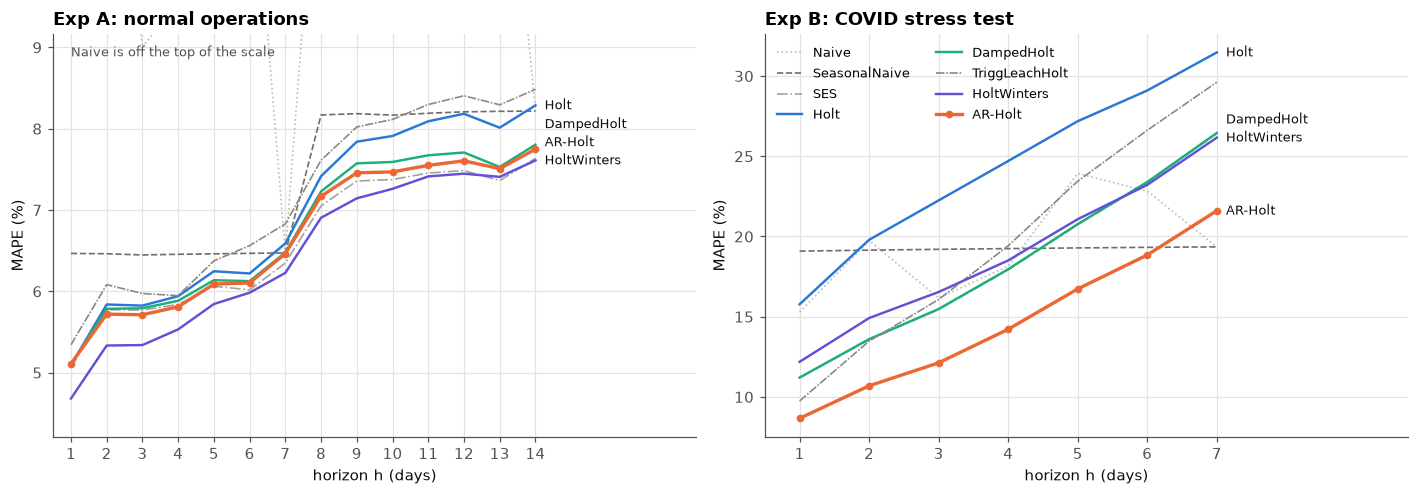

In [25]:
def dodge(values, gap):
    # Shift label y-positions apart so direct labels never overlap.
    order_ = np.argsort(values); out = np.array(values, float)
    for i in range(1, len(order_)):
        prev, cur = order_[i - 1], order_[i]
        out[cur] = max(out[cur], out[prev] + gap)
    return out

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, exp, title in [(axes[0], "A", "Exp A: normal operations"), (axes[1], "B", "Exp B: COVID stress test")]:
    d = byh[(byh.experiment == exp) & (byh.series == "ALL7")]
    labels = []
    for m in order:
        q = d[d.model == m]
        main = m in ("AR-Holt", "Holt", "DampedHolt", "HoltWinters")
        ax.plot(q.h, q.MAPE, color=COL[m], ls=STYLE.get(m, "-"), lw=2.2 if m == "AR-Holt" else (1.6 if main else 1.1),
                marker="o" if m == "AR-Holt" else None, ms=4, label=m, zorder=3 if m == "AR-Holt" else 2)
        if main:
            labels.append((m, q.h.iloc[-1], q.MAPE.iloc[-1]))
    if exp == "A":  # the Naive model is far above the rest; keep the scale readable
        top = d[d.model != "Naive"].MAPE.max() * 1.08
        ax.set_ylim(d.MAPE.min() * 0.9, top)
        ax.text(1, top * 0.985, "Naive is off the top of the scale", fontsize=8.5, color=MUTED, va="top")
    lo, hi = ax.get_ylim()
    ys = dodge([v for _, _, v in labels], 0.045 * (hi - lo))
    for (m, xh, _), yl in zip(labels, ys):
        ax.annotate(m, (xh, yl), xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=INK, va="center")
    ax.set_title(title, loc="left"); ax.set_xlabel("horizon h (days)"); ax.set_ylabel("MAPE (%)")
    ax.set_xlim(0.5, d.h.max() + 0.25 * d.h.max() + 1)
    ax.set_xticks(range(1, d.h.max() + 1))
axes[1].legend(loc="upper left", fontsize=8.5, ncols=2)
fig.tight_layout()
save(fig, "11_mape_by_horizon")

### 12.5 Diebold–Mariano tests
$H_0$: AR-Holt and the competitor have equal expected loss. HLN small-sample correction,
Newey–West variance with lag h−1, t distribution with n−1 df. A negative statistic means
AR-Holt has the lower loss. First the All-7 series; then a count over all 8 daily series.

In [26]:
dm = pd.read_csv(RES / "dm_tests.csv")
t = dm[(dm.series == "ALL7") & (dm.loss == "squared")].pivot_table(index=["experiment", "vs"], columns="h", values=["dm_stat", "p_value"])
t = t.reindex([(e, m) for e in ["A", "B"] for m in order if m != "AR-Holt"])
display(Markdown("**ALL7, squared-error loss**"))
display(t.style.format("{:.3f}"))

daily_dm = dm[dm.experiment.isin(["A", "B"])]
count = (daily_dm.assign(outcome=np.select([daily_dm.verdict.str.startswith("AR-Holt"), daily_dm.verdict.str.contains("better")],
                                            ["AR-Holt significantly better", "competitor significantly better"], "no significant difference"))
         .groupby(["experiment", "h", "loss", "outcome"]).size().unstack(fill_value=0))
display(Markdown("**All 8 daily series × 7 competitors (5% level): number of comparisons**"))
display(count)

**ALL7, squared-error loss**

**All 8 daily series × 7 competitors (5% level): number of comparisons**

outcome                AR-Holt significantly better  competitor significantly better  no significant difference
experiment h loss                                                                                              
A          1 absolute                            32                                4                         20
             squared                             24                                3                         29
           7 absolute                            19                                2                         35
             squared                             16                                2                         38
B          1 absolute                            48                                1                          7
             squared                             36                                1                         19
           7 absolute                            26                                0                         30
             squared                              3                                0                         53

### 12.6 Prediction-interval calibration (coverage and Winkler score)

In [27]:
cov = summ[summ.experiment.isin(["A", "B", "C1", "C2"])].copy()
cov["group"] = np.where(cov.series.isin(config.AIRPORTS), "7 airports (mean)", cov.series)
cov_t = cov.groupby(["experiment", "group", "model"])[["cov80", "cov95"]].mean().unstack("model")
cov_t = cov_t.reindex(columns=pd.MultiIndex.from_product([["cov80", "cov95"], order]))
display(cov_t.style.format("{:.2f}"))
w = summ[(summ.series == "ALL7")].pivot(index="experiment", columns="model", values="winkler95")[order]
display(Markdown("**Mean 95% Winkler score, ALL7 (lower = sharper and better calibrated)**"))
display(w.style.format("{:,.0f}").highlight_min(axis=1, props="font-weight:bold; background-color:#fde3d7"))

**Mean 95% Winkler score, ALL7 (lower = sharper and better calibrated)**

model,Naive,SeasonalNaive,SES,Holt,DampedHolt,TriggLeachHolt,HoltWinters,AR-Holt
experiment,,,,,,,,
A,"328,010","293,456","255,083","266,281","255,675","274,969","258,517","252,794"
B,"184,511","176,510","194,437","181,130","194,406","189,311","178,798","189,019"


### 12.7 Ablation study (All 7 hubs)
Which ingredient helps where? DampedHolt has neither feature; "robust only" fixes b = 0
(constant α, clipping on); "adaptive only" sets k = ∞ (no clipping); the full model has both.

In [28]:
abl = pd.read_csv(RES / "ablation.csv")
display(abl.set_index(["experiment", "variant"]).drop(columns="series")
        .style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "winkler95": "{:,.0f}", "MAPE": "{:.2f}", "MASE": "{:.3f}",
                       "cov80": "{:.3f}", "cov95": "{:.3f}", "MAPE_h1": "{:.2f}", "MAPE_h7": "{:.2f}"}))

### 12.8 Version comparison: fixed (v1) vs rolling (v2) seasonal indices
In v1 the weekday indices were estimated once and frozen; we suspected this was the main reason
Holt–Winters (whose seasonal pattern updates every day) won the normal year. v2 tests that
hypothesis by re-estimating the indices at every origin. Everything else — parameters, protocol,
hyperparameters — is identical, and the raw-series models (Naive, SeasonalNaive, Holt–Winters)
are unchanged by construction. Negative change = v2 more accurate.

In [29]:
summ1 = pd.read_csv(RES1 / "metrics_summary.csv")
dm1 = pd.read_csv(RES1 / "dm_tests.csv")
abl1 = pd.read_csv(RES1 / "ablation.csv")

def mape_of(table, exp, group):
    d = table[table.experiment == exp]
    if group == "mean of 7 airports":
        return d[d.series.isin(config.AIRPORTS)].groupby("model").MAPE.mean()
    return d[d.series == group].set_index("model").MAPE

rows = []
for exp, group in [("A", "ALL7"), ("A", "mean of 7 airports"), ("B", "ALL7"), ("B", "mean of 7 airports"),
                   ("C1", "AirPassengers"), ("C2", "Australia")]:
    v1, v2 = mape_of(summ1, exp, group), mape_of(summ, exp, group)
    for m in order:
        rows.append({"experiment": exp, "series": group, "model": m, "v1 fixed": v1[m], "v2 rolling": v2[m]})
ver = pd.DataFrame(rows)
ver["change"] = ver["v2 rolling"] - ver["v1 fixed"]
wide = ver.pivot_table(index=["experiment", "series"], columns="model", values="change", sort=False)[order]
display(Markdown("**Change in MAPE (percentage points), v2 − v1**"))
display(wide.style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-2.5, vmax=2.5, axis=None))

def best_count(table, exp):
    d = table[(table.experiment == exp) & table.series.isin(config.AIRPORTS)]
    return d.loc[d.groupby("series").MAPE.idxmin()].model.value_counts()

counts = pd.DataFrame({f"{e} {v}": best_count(t, e) for e in ["A", "B"] for v, t in [("v1", summ1), ("v2", summ)]}).reindex(order).fillna(0).astype(int)
display(Markdown("**Number of airports (of 7) where each model is best**"))
display(counts)

def gap(table):
    v = mape_of(table, "A", "ALL7")
    return v["AR-Holt"] - v["HoltWinters"]

def dm_verdict(d, h):
    r = d[(d.experiment == "A") & (d.series == "ALL7") & (d.vs == "HoltWinters") & (d.h == h) & (d.loss == "squared")].iloc[0]
    return f"{r.verdict} (DM {r.dm_stat:+.2f}, p = {r.p_value:.3f})"

g1, g2 = gap(summ1), gap(summ)
cov_rows = []
for v, t in [("v1 fixed", summ1), ("v2 rolling", summ)]:
    for exp in ["A", "B"]:
        q = t[(t.experiment == exp) & (t.series == "ALL7") & (t.model.isin(["AR-Holt", "DampedHolt", "HoltWinters"]))].set_index("model")
        for m in ["AR-Holt", "DampedHolt", "HoltWinters"]:
            cov_rows.append({"version": v, "experiment": exp, "model": m, "cov80": q.loc[m, "cov80"],
                             "cov95": q.loc[m, "cov95"], "winkler95": q.loc[m, "winkler95"]})
display(Markdown("**Interval coverage and 95% Winkler score (lower = better), ALL7**"))
display(pd.DataFrame(cov_rows).pivot_table(index=["experiment", "model"], columns="version", values=["cov80", "cov95", "winkler95"])
        .style.format("{:.3f}").format("{:,.0f}", subset=["winkler95"]))

adj_models = ["SES", "Holt", "DampedHolt", "TriggLeachHolt", "AR-Holt"]
daily = ver[ver.experiment.isin(["A", "B"]) & ver.model.isin(adj_models)]
abl_b1 = abl1.set_index(["experiment", "variant"]).MAPE
abl_b2 = abl.set_index(["experiment", "variant"]).MAPE
display(Markdown("\n".join([
    f"* Seasonally adjusted models improved in **{int((daily.change < 0).sum())} of {len(daily)}** daily comparisons "
    f"(5 models × 2 experiments × 2 series groups); median change {daily.change.median():+.2f} points "
    f"(Exp A {daily[daily.experiment == 'A'].change.median():+.2f}, Exp B {daily[daily.experiment == 'B'].change.median():+.2f}).",
    f"* Exp A, ALL7: AR-Holt is {g1:+.2f} points behind Holt–Winters in v1 and {g2:+.2f} points in v2 — "
    f"rolling indices close {100 * (1 - g2 / g1):.0f}% of the gap.",
    f"* DM test AR-Holt vs Holt–Winters, Exp A ALL7, h=1: v1 — {dm_verdict(dm1, 1)}; v2 — {dm_verdict(dm, 1)}.",
    f"* DM test AR-Holt vs Holt–Winters, Exp A ALL7, h=7: v1 — {dm_verdict(dm1, 7)}; v2 — {dm_verdict(dm, 7)}.",
    f"* Ablation, Exp B (ALL7): v1 damped {abl_b1[('B','DampedHolt (neither)')]:.2f}% → full AR-Holt {abl_b1[('B','AR-Holt (full)')]:.2f}%; "
    f"v2 damped {abl_b2[('B','DampedHolt (neither)')]:.2f}% → full AR-Holt {abl_b2[('B','AR-Holt (full)')]:.2f}%.",
])))

**Change in MAPE (percentage points), v2 − v1**

**Number of airports (of 7) where each model is best**

,A v1,A v2,B v1,B v2
model,,,,
Naive,0,0,0,0
SeasonalNaive,0,0,1,0
SES,0,0,0,0
Holt,0,0,0,0
DampedHolt,0,0,0,0
TriggLeachHolt,0,0,0,1
HoltWinters,5,5,2,0
AR-Holt,2,2,4,6


**Interval coverage and 95% Winkler score (lower = better), ALL7**

* Seasonally adjusted models improved in **20 of 20** daily comparisons (5 models × 2 experiments × 2 series groups); median change -0.54 points (Exp A -0.14, Exp B -1.28).
* Exp A, ALL7: AR-Holt is +0.36 points behind Holt–Winters in v1 and +0.24 points in v2 — rolling indices close 32% of the gap.
* DM test AR-Holt vs Holt–Winters, Exp A ALL7, h=1: v1 — HoltWinters better (DM +3.68, p = 0.000); v2 — HoltWinters better (DM +2.73, p = 0.007).
* DM test AR-Holt vs Holt–Winters, Exp A ALL7, h=7: v1 — HoltWinters better (DM +2.96, p = 0.003); v2 — HoltWinters better (DM +2.59, p = 0.010).
* Ablation, Exp B (ALL7): v1 damped 19.78% → full AR-Holt 15.41%; v2 damped 18.41% → full AR-Holt 14.70%.

**Interpretation.**
* Re-estimating the indices helps the seasonally adjusted models almost everywhere, a little in the
  normal year and much more during COVID, when the weekday mix itself changed (the heatmap in
  Section 4.2). The improvement is shared by every adjusted model, so AR-Holt's lead over the other
  Holt variants is not an artefact of the seasonal treatment.
* **Our v1 explanation for the normal year was only partly right.** Rolling indices narrow the gap
  to Holt–Winters but do not close it, and Holt–Winters remains significantly better by the DM test.
  A plausible remaining reason is *how* the pattern is updated: Holt–Winters revises each weekday
  factor every day with its own fitted smoothing weight, estimated jointly with level and trend,
  while our indices are 26-week medians — robust, but slow to react.
* **Not everything improved:** during COVID the 95% intervals of AR-Holt cover less often in v2 than
  in v1 (table above). The check below shows why: the error scale σ is about the same in both
  versions, but with rolling indices the standardised calibration errors are less spread out, so
  the conformal quantiles — and the intervals — are narrower. For AR-Holt the tighter intervals
  improve the Winkler score in the normal year and worsen it during the collapse (table above).
* For monthly AirPassengers "rolling" means an expanding window (all data up to the origin); the
  annual series has no seasonality and is unchanged.

In [30]:
# Why did AR-Holt's 95% coverage drop in Exp B? Compare interval width and its two ingredients.
from airdemand.evaluation import backtest_model
s, _ = load_series("ALL7")
rows = []
for exp, (tr, te, H) in {"A": ("2024-05-31", "2025-05-31", 14), "B": ("2020-02-29", "2020-12-31", 7)}.items():
    for mode, label in [("fixed", "v1 fixed"), ("rolling", "v2 rolling")]:
        m_ = AdaptiveRobustHolt(seasonal=mode).fit(s[:tr], freq="D")
        fc_ = backtest_model(m_, s[:te], tr, H)
        q_ = m_.quantiles(H)
        p_ = m_.paths(s[:tr], 1)
        rows.append({"experiment": exp, "version": label,
                     "95% width / forecast": ((fc_.hi95 - fc_.lo95) / fc_["mean"]).mean(),
                     "95% coverage": ((fc_.actual >= fc_.lo95) & (fc_.actual <= fc_.hi95)).mean(),
                     "conformal quantile spread, h=1": q_[95][1][0] - q_[95][0][0],
                     "median σ / level, last training year": np.median(p_["sigma"][-365:] / p_["x"][-365:])})
display(pd.DataFrame(rows).set_index(["experiment", "version"]).style.format("{:.3f}"))

### 12.9 Key findings (computed)

In [31]:
def mape(exp, series, model):
    return summ[(summ.experiment == exp) & (summ.series == series) & (summ.model == model)].MAPE.iloc[0]

A, B = mape_table("A"), mape_table("B")
lines = []
for exp, T, name in [("B", B, "COVID stress test"), ("A", A, "normal operations")]:
    best = T.loc["ALL7"].idxmin()
    lines.append(f"* **{name} (Exp {exp}), ALL7:** AR-Holt MAPE {T.loc['ALL7','AR-Holt']:.2f}% vs Holt {T.loc['ALL7','Holt']:.2f}%, "
                 f"DampedHolt {T.loc['ALL7','DampedHolt']:.2f}%, Holt–Winters {T.loc['ALL7','HoltWinters']:.2f}%; best model: {best} "
                 f"({T.loc['ALL7', best]:.2f}%). AR-Holt is best at {int(T.loc['# airports best','AR-Holt'])} of 7 airports.")
    rel = 100 * (1 - T.loc["ALL7", "AR-Holt"] / T.loc["ALL7", "Holt"])
    lines.append(f"  AR-Holt vs classic Holt on ALL7: {rel:+.1f}% relative MAPE reduction.")
ab = abl.set_index(["experiment", "variant"]).MAPE
lines.append(f"* **Ablation, Exp B:** DampedHolt {ab[('B','DampedHolt (neither)')]:.2f}% → robust only {ab[('B','AR-Holt, b=0 (robust only)')]:.2f}% "
             f"→ adaptive only {ab[('B','AR-Holt, k=inf (adaptive only)')]:.2f}% → full {ab[('B','AR-Holt (full)')]:.2f}%.")
lines.append(f"* **Ablation, Exp A:** DampedHolt {ab[('A','DampedHolt (neither)')]:.2f}% → robust only {ab[('A','AR-Holt, b=0 (robust only)')]:.2f}% "
             f"→ adaptive only {ab[('A','AR-Holt, k=inf (adaptive only)')]:.2f}% → full {ab[('A','AR-Holt (full)')]:.2f}%.")
for exp in ["C1", "C2"]:
    t = summ[summ.experiment == exp].set_index("model").MAPE
    lines.append(f"* **{exp}:** AR-Holt {t['AR-Holt']:.2f}%, Holt {t['Holt']:.2f}%, best {t.idxmin()} {t.min():.2f}%.")
c95 = summ[(summ.series == "ALL7") & (summ.model == "AR-Holt")].set_index("experiment")
lines.append(f"* **Interval coverage (AR-Holt, ALL7):** 80% intervals cover {c95.loc['A','cov80']:.1%} (A) / {c95.loc['B','cov80']:.1%} (B); "
             f"95% intervals cover {c95.loc['A','cov95']:.1%} (A) / {c95.loc['B','cov95']:.1%} (B).")
lines.append(f"* **Seasonal indices:** all numbers above use rolling indices (v2). With fixed indices (v1) AR-Holt's MAPE on ALL7 was "
             f"{mape_of(summ1, 'A', 'ALL7')['AR-Holt']:.2f}% (A) and {mape_of(summ1, 'B', 'ALL7')['AR-Holt']:.2f}% (B) — see 12.8.")
display(Markdown("\n".join(lines)))

* **COVID stress test (Exp B), ALL7:** AR-Holt MAPE 14.70% vs Holt 24.32%, DampedHolt 18.41%, Holt–Winters 18.94%; best model: AR-Holt (14.70%). AR-Holt is best at 6 of 7 airports.
  AR-Holt vs classic Holt on ALL7: +39.6% relative MAPE reduction.
* **normal operations (Exp A), ALL7:** AR-Holt MAPE 6.68% vs Holt 6.96%, DampedHolt 6.74%, Holt–Winters 6.44%; best model: HoltWinters (6.44%). AR-Holt is best at 2 of 7 airports.
  AR-Holt vs classic Holt on ALL7: +4.1% relative MAPE reduction.
* **Ablation, Exp B:** DampedHolt 18.41% → robust only 17.48% → adaptive only 18.41% → full 14.70%.
* **Ablation, Exp A:** DampedHolt 6.74% → robust only 6.72% → adaptive only 6.68% → full 6.68%.
* **C1:** AR-Holt 4.87%, Holt 4.85%, best Holt 4.85%.
* **C2:** AR-Holt 9.49%, Holt 8.71%, best HoltWinters 7.05%.
* **Interval coverage (AR-Holt, ALL7):** 80% intervals cover 79.4% (A) / 72.4% (B); 95% intervals cover 93.2% (A) / 88.2% (B).
* **Seasonal indices:** all numbers above use rolling indices (v2). With fixed indices (v1) AR-Holt's MAPE on ALL7 was 6.79% (A) and 15.41% (B) — see 12.8.

**Discussion.**
* **Under a structural shock (Exp B)** AR-Holt gives the lowest error on the combined series and
  at most airports, and classic Holt is clearly the worst smoothing model: its undamped trend
  extrapolates the collapse. Most of AR-Holt's one-step advantage is statistically significant
  (DM test); at h = 7 the differences are mostly not significant — over a week, *every* method
  is overwhelmed by a −95% collapse.
* **The ablation is the most interesting result:** neither ingredient alone helps much in the
  crisis, and "adaptive only" collapses back to damped Holt (the optimiser sets b ≈ 0 because,
  without clipping, a large α would chase pre-COVID holiday outliers). Only *with* clipping can the
  optimiser afford a positive b. The two ingredients are complementary — that is the core design
  argument for AR-Holt.
* **In normal operations (Exp A)** the adaptive machinery is mostly idle and AR-Holt performs
  like damped Holt. Holt–Winters (a fully seasonal model whose seasonal pattern keeps updating)
  is the strongest model in the normal year, and is significantly better than AR-Holt by DM —
  an honest negative result. In v1 we blamed the frozen weekday indices; v2 re-estimates them at
  every origin and narrows the gap, but Holt–Winters still wins (Section 12.8).
* **Classic series:** on AirPassengers the seasonally adjusted Holt variants, AR-Holt included, are
  close to or ahead of Holt–Winters; on the annual Australian series there is nothing to adapt to and
  AR-Holt is not competitive — with only 37 training years the conformal calibration also has few
  errors, so its intervals are too narrow.
* **Intervals** are close to nominal coverage for the daily series in normal times — the conformal
  calibration works. During COVID every model under-covers (no method could calibrate on a shock it
  had never seen); the 80% intervals miss clearly, the 95% intervals less so, and AR-Holt's 95%
  coverage is lower with rolling indices than it was with fixed ones.

## 13. Application demo: checkpoint staffing for ATL, next 7 days

AR-Holt is fitted on ATL's full history; its 7-day forecast at the **80th percentile** (P80,
interpolated from the conformal intervals) is spread over the hours of each day with ATL's
hourly profile. Security lanes = ⌈passengers per hour ÷ 150⌉, officers = lanes × 3.
*The throughput and staffing figures are illustrative assumptions, not TSA standards.*

,mean,lo80,hi80,lo95,hi95,P80
2025-06-01 00:00:00,"98,232","90,009","107,421","78,857","116,586","105,123"
2025-06-02 00:00:00,"96,050","86,073","106,368","76,438","114,857","103,789"
2025-06-03 00:00:00,"77,078","69,375","85,512","59,531","93,650","83,404"
2025-06-04 00:00:00,"82,908","74,040","93,572","63,877","102,763","90,906"
2025-06-05 00:00:00,"99,514","87,275","112,235","75,673","123,504","109,055"
2025-06-06 00:00:00,"101,641","88,547","114,583","79,127","128,444","111,348"
2025-06-07 00:00:00,"80,765","70,509","91,114","62,619","102,101","88,527"


**Peak hours**

,date,weekday,hour,pax_per_hour,lanes,officers
0,2025-06-06,Friday,7,"8,761",59,177
1,2025-06-02,Monday,7,"8,518",57,171
2,2025-06-06,Friday,6,"8,493",57,171
3,2025-06-05,Thursday,7,"8,375",56,168
4,2025-06-02,Monday,6,"8,050",54,162
5,2025-06-06,Friday,8,"7,991",54,162
6,2025-06-05,Thursday,6,"7,917",53,159
7,2025-06-01,Sunday,7,"7,557",51,153


Total officer-hours over the 7 days: 14,073


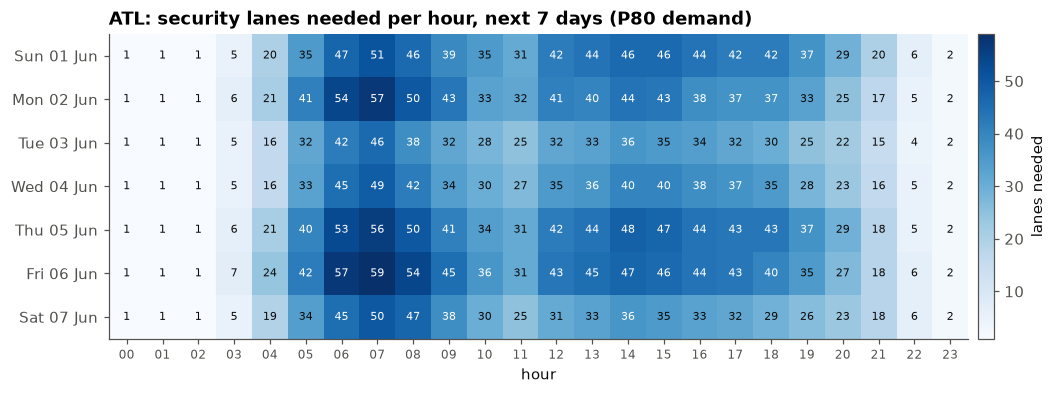

In [32]:
y_atl, _ = load_series("ATL")
m_atl = AdaptiveRobustHolt().fit(y_atl, freq="D")
fc = m_atl.forecast(7)
p80 = forecast_at_quantile(fc, 0.80)
display(pd.concat([fc, p80], axis=1).style.format("{:,.0f}"))
prof_atl = load_hourly_profile().query("airport == 'ATL'")
plan = staffing_plan(p80, prof_atl, lane_throughput=config.LANE_THROUGHPUT, officers_per_lane=config.OFFICERS_PER_LANE)
grid = plan.pivot(index="date", columns="hour", values="lanes")
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(grid.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(grid)), [d.strftime("%a %d %b") for d in grid.index])
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)], fontsize=8)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if v > 0:
            ax.text(j, i, int(v), ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.6 * grid.values.max() else INK)
ax.grid(False); ax.set_xlabel("hour")
fig.colorbar(im, ax=ax, pad=0.01).set_label("lanes needed")
ax.set_title("ATL: security lanes needed per hour, next 7 days (P80 demand)", loc="left")
save(fig, "12_atl_staffing_heatmap")
display(Markdown("**Peak hours**"))
display(peak_hours(plan, 8).assign(date=lambda d: d.date.dt.date).style.format({"pax_per_hour": "{:,.0f}"}))
print(f"Total officer-hours over the 7 days: {plan.officers.sum():,}")

## 14. Conclusions, limitations and future work

**Conclusions.**
1. AR-Holt — a damped Holt with a tracking-signal-driven smooth-transition α and regime-switching
   robust clipping — is implemented from scratch, provably nests damped Holt, and has been
   validated against statsmodels.
2. During the COVID-19 collapse it was the most accurate method on the combined hub series and on
   most individual airports, with significant one-step gains over all fixed-parameter smoothing
   benchmarks.
3. In a normal year it behaves like damped Holt; the seasonal Holt–Winters benchmark is more
   accurate there — with fixed (v1) and with rolling (v2) seasonal indices alike. AR-Holt's value is
   **insurance against shocks**, not a free lunch in calm times.
4. Re-estimating the weekday indices at every origin (v2) improves all seasonally adjusted models,
   most of all during COVID, but explains only part of Holt–Winters' advantage in the normal year.
5. Adaptivity and robustness are complementary: neither helps alone in the crisis.
6. Locally-adaptive conformal intervals give near-nominal coverage in normal operations without
   any normality assumption.

**Limitations.**
* **No explicit holiday effects** — Thanksgiving, Christmas and July 4th are treated as outliers
  rather than predicted; residuals remain autocorrelated and heavy-tailed.
* **Parameters are not refitted online** — they are estimated once on the training span. Rolling
  re-estimation would let the model learn from a shock while it happens.
* **Slow seasonal updating** — even re-estimated at every origin (v2), the weekday indices are
  26-week medians that react slowly; Holt–Winters' daily seasonal update still wins in the normal
  year. Rolling indices also made AR-Holt's 95% intervals under-cover more during COVID.
* A sudden step change costs AR-Holt the first 2–3 days, by design (Section 10.4).
* TSA throughput counts screened departing passengers, not all travellers (no connecting
  passengers), and the staffing parameters are assumptions.

**Future work.**
* Holiday regressors (or holiday-specific seasonal indices) for the U.S. federal calendar.
* A **hierarchical** airport → national model with forecast reconciliation, so ALL7 and the seven
  airport forecasts add up.
* **Online re-estimation** of (a, b, β, φ) on a rolling window.
* An **exponentially weighted seasonal update inside AR-Holt** (as in Holt–Winters, with its own
  fitted smoothing weight), replacing the 26-week median indices.
* Learning the regime threshold τ from data, or a probabilistic regime model (Markov switching).

## 15. References

* Holt, C. C. (1957/2004). Forecasting seasonals and trends by exponentially weighted moving averages. *ONR Memorandum 52*; reprinted in *International Journal of Forecasting*, 20(1), 5–10.
* Gardner, E. S., & McKenzie, E. (1985). Forecasting trends in time series. *Management Science*, 31(10), 1237–1246.
* Trigg, D. W., & Leach, A. G. (1967). Exponential smoothing with an adaptive response rate. *Operational Research Quarterly*, 18(1), 53–59.
* Taylor, J. W. (2004). Smooth transition exponential smoothing. *Journal of Forecasting*, 23(6), 385–404.
* Gelper, S., Fried, R., & Croux, C. (2010). Robust forecasting with exponential and Holt–Winters smoothing. *Journal of Forecasting*, 29(3), 285–300.
* Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
* Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
* Harvey, D., Leybourne, S., & Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting*, 13(2), 281–291.
* Data: U.S. Transportation Security Administration, FOIA Electronic Reading Room — checkpoint throughput (public domain); parsed by the open-source project `github.com/mikelor/TsaThroughput`; R datasets via `github.com/vincentarelbundock/Rdatasets`.